# 03 · Elastic Net: cross-sector return prediction

**Scope of this contribution: Elastic Net modelling, time-ordered validation and evaluation of forecast accuracy.**

Continue the frozen outputs of notebooks 01–02. This notebook ends at model forecasts, prediction diagnostics and export to yae. Portfolio construction, threshold selection, position persistence, SPY netting and cost-aware evaluation belong to yae's unified backtest.

**Economic hypothesis.** Information may diffuse across related sectors, while overlapping windows and shared market states create correlated predictors. Elastic Net combines sparse selection (L1) and coefficient stabilization (L2). This is a predictive hypothesis, not causal identification. For standardized inputs, sklearn minimizes

$$
\frac{1}{2n}\|y-b-X\beta\|_2^2+
\alpha\rho\|\beta\|_1+\frac{\alpha(1-\rho)}{2}\|\beta\|_2^2.
$$

The intercept is unpenalized; the target stays in decimal-return units. Cyclic coordinate descent follows the [official ElasticNet implementation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html).

S0 has 57 own-sector and shared market-state inputs; S1 has 97 inputs adding other sectors; S2 has 102 adding relationship summaries. All three pre-specified schemes are retained. There is no overall scheme winner.

**Elastic Net specification.** Both the main expanding-window model and Section 9 use the same grid: $\rho \in \{0.2,0.4,0.6,0.8\}$ and $\alpha \in \{10^{-5},10^{-4},10^{-3}\}$. Parameters are selected using 2018–2022 validation only and held fixed for the 2023–September 2026 evaluation. Section 9 compares training windows and Ridge using validation data; it does not select a replacement test model. All outputs below come from a single end-to-end run; software versions and input hashes are recorded in run_manifest.json.

## 1. Environment & configuration

Python 3.12.10 / scikit-learn 1.9.1. Set $\rho \in \{0.2,0.4,0.6,0.8\}$ (`l1_ratio`) throughout the notebook. With three alpha values, there are 12 parameter pairs per scheme and 36 scheme/parameter combinations across S0/S1/S2. The main validation search contains 19,440 monthly-sector fits. Lock one pair per scheme using pooled validation MSE before evaluating the test period. Section 9 reuses this same parameter grid for every training window.

In [1]:
from pathlib import Path
import json, hashlib, platform, warnings, time, io
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / 'data/processed/panel_spec.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/processed/panel_spec.json').exists(), 'Run from repository root or notebooks/'
OUT = ROOT / 'results/elastic_net'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 5205
np.random.seed(SEED)
SCHEMES = ['S0', 'S1', 'S2']
ALPHAS = [1e-5, 1e-4, 1e-3]
L1_RATIOS = [0.2, 0.4, 0.6, 0.8]
GRID = [(a, r) for a in ALPHAS for r in L1_RATIOS]
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
spec = json.loads((ROOT/'data/processed/panel_spec.json').read_text())
SECTORS = sorted(spec['input_files'])
paths = [ROOT/'data/processed/panel_spec.json', ROOT/spec['shared_panel'],
         ROOT/'notebooks/panel_checks/monthly_training_eligibility.csv']
paths += [ROOT/path for by_scheme in spec['input_files'].values() for path in by_scheme.values()]
source_hashes = {str(path.relative_to(ROOT)):sha(path) for path in paths}
config = dict(seed=SEED, alphas=ALPHAS, l1_ratios=L1_RATIOS,
              selection='pooled validation MSE per specification; tie: larger alpha then larger l1_ratio',
              retained_schemes=SCHEMES, target_units='decimal returns',
              scope='Elastic Net forecasting and prediction diagnostics; validation selects parameters',
              reproduction_provenance='Single end-to-end run; software versions and input hashes recorded in run_manifest.json',
              preprocessing='StandardScaler fit on mature expanding training rows only',
              refit='monthly, at prior SPY trading day 18:00 New York',
              grid_candidates_per_spec=len(GRID), total_candidates=3*len(GRID),
              source_hashes=source_hashes)
# Save the complete grid and selection rule before this run generates forecasts.
(OUT/'design_config.json').write_text(json.dumps(config, indent=2)+'\n')
print('Python', platform.python_version(), '| sklearn', sklearn.__version__)
print('Grid:', GRID, '| 36 specification/parameter combinations; 9 sector models each')

from threadpoolctl import threadpool_limits
_numerical_threads = threadpool_limits(limits=1)

Python 3.12.10 | sklearn 1.9.1
Grid: [(1e-05, 0.2), (1e-05, 0.4), (1e-05, 0.6), (1e-05, 0.8), (0.0001, 0.2), (0.0001, 0.4), (0.0001, 0.6), (0.0001, 0.8), (0.001, 0.2), (0.001, 0.4), (0.001, 0.6), (0.001, 0.8)] | 36 specification/parameter combinations; 9 sector models each


## 2. Load shared panel and feature files

Signals use data available at 18:00 New York time. The target is next-open to following-open sector cash return minus SPY cash return. Join only on `(date, ticker)`; metadata and realized outcomes are never predictors. Use the shared common-feature mask for training/prediction and the common-scoreable mask for evaluation. Keep forecasts for the final two signal dates even though they lack future labels.

In [2]:
panel = pd.read_csv(ROOT/spec['shared_panel'], parse_dates=['date','entry_date','exit_date'],
                    float_precision='round_trip')
for c in ['signal_at', 'entry_at', 'label_available_at']:
    panel[c] = pd.to_datetime(panel[c], utc=True).dt.tz_convert('America/New_York')
assert not panel.duplicated(['date','ticker']).any()
calendar = pd.DatetimeIndex(sorted(panel.date.unique()))
data = {}
for ticker in SECTORS:
    info = panel.loc[panel.ticker.eq(ticker)].sort_values('date').reset_index(drop=True)
    xs = {}
    for scheme in SCHEMES:
        f = pd.read_csv(ROOT/spec['input_files'][ticker][scheme], parse_dates=['date'],
                        float_precision='round_trip')
        cols = spec['predictors_by_target'][ticker][scheme]
        assert len(cols) == spec['predictor_counts'][scheme]
        assert list(f.columns) == ['date','ticker'] + cols
        assert f[['date','ticker']].equals(info[['date','ticker']])
        assert not set(cols).intersection(spec['columns_not_predictors'])
        xs[scheme] = f[cols].to_numpy(dtype=float)
        assert np.isfinite(xs[scheme][info.common_features_valid]).all()
    data[ticker] = (info, xs)

def training_mask(info, cutoff):
    return (info.date.ge(pd.Timestamp('2008-01-01')) & info.common_features_valid
            & info.label_valid & info.signal_at.le(cutoff)
            & info.label_available_at.le(cutoff)).to_numpy()

schedule = {}
for month in pd.period_range('2018-01','2026-09', freq='M'):
    dates = calendar[calendar.to_period('M') == month]
    prior = calendar[calendar.get_loc(dates[0])-1]
    schedule[str(month)] = (prior + pd.Timedelta(hours=18)).tz_localize('America/New_York')

coverage = panel.groupby('split')[['common_features_valid','common_scoreable']].sum()
display(coverage)
coverage.to_csv(OUT/'sample_coverage.csv')

,common_features_valid,common_scoreable
split,,
test,8451,8433
train,21930,21911
validation,11331,11313
warmup,1476,0


## 3. Leakage-safe monthly training

Training starts in 2008. Validation: 2018–2022; test: 2023–September 2026. Fit once per month at the previous SPY trading day's 18:00 New York timestamp. Both the training signal and its label must be known by that cutoff. Mature labels crossing a partition boundary remain eligible for later fits. Monthly test refitting can use already realized test-period labels, with all hyperparameters fixed.

Fit StandardScaler only on eligible historical training rows. The target is not standardized. No random CV, full-sample scaling, imputation or fitted outlier treatment is introduced. Nonconvergence triggers a numerical retry and then an error, never acceptance of an unconverged result.

In [3]:
fit_audit, coefficient_rows = [], []
def fit_model(X, y, alpha, ratio):
    # Retry only for numerical convergence, never for a better score.
    for max_iter in (10000, 100000, 1000000):
        model = ElasticNet(alpha=alpha, l1_ratio=ratio, fit_intercept=True,
                           max_iter=max_iter, tol=1e-6, selection='cyclic',
                           random_state=SEED, precompute=True)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            model.fit(X, y)
        if not any(issubclass(w.category, ConvergenceWarning) for w in caught):
            model.max_iter_used_ = max_iter
            return model
    raise RuntimeError('Coordinate descent failed to converge; no results accepted.')

def forecast(split, candidates, keep_coefficients=False):
    rows = []
    months = [m for m in schedule if ('2018' <= m[:4] <= '2022') == (split == 'validation')]
    for mi, month in enumerate(months):
        cutoff = schedule[month]
        for ticker in SECTORS:
            info, xs = data[ticker]
            train = training_mask(info, cutoff)
            pred = (info.date.dt.to_period('M').astype(str).eq(month)
                    & info.common_features_valid & info['split'].eq(split)).to_numpy()
            assert train.sum() >= 1000 and pred.any()
            assert info.loc[train,'label_available_at'].max() <= cutoff
            assert info.loc[pred,'signal_at'].min() > cutoff
            y = info.loc[train,'target_relative_return'].to_numpy()
            for scheme in SCHEMES:
                scaler = StandardScaler()
                Xtrain = np.asfortranarray(scaler.fit_transform(xs[scheme][train]))
                Xpred = scaler.transform(xs[scheme][pred])
                for alpha, ratio in candidates[scheme]:
                    model = fit_model(Xtrain, y, alpha, ratio)
                    output = info.loc[pred, ['date','ticker','split','common_scoreable',
                        'entry_date','exit_date','target_relative_return',
                        'sector_forward_cash_return','spy_forward_cash_return']].copy()
                    output['scheme'], output['alpha'], output['l1_ratio'] = scheme, alpha, ratio
                    output['y_hat'] = model.predict(Xpred)
                    output['historical_mean'] = y.mean()
                    output['fit_cutoff'] = cutoff
                    rows.append(output)
                    fit_audit.append(dict(split=split, month=month, ticker=ticker, scheme=scheme,
                        alpha=alpha, l1_ratio=ratio, fit_at=cutoff, training_rows=int(train.sum()),
                        latest_training_signal=info.loc[train,'date'].max(),
                        latest_label_available_at=info.loc[train,'label_available_at'].max(),
                        first_prediction_signal=info.loc[pred,'signal_at'].min(),
                        nonzero=int(np.count_nonzero(model.coef_)),
                        l1_norm=float(np.linalg.norm(model.coef_,1)),
                        l2_norm=float(np.linalg.norm(model.coef_,2)),
                        largest_abs_coefficient=float(np.max(np.abs(model.coef_))),
                        n_iter=int(model.n_iter_), max_iter_used=model.max_iter_used_,
                        convergence_retry_count=[10000,100000,1000000].index(model.max_iter_used_),
                        dual_gap=float(model.dual_gap_)))
                    if keep_coefficients:
                        for f, b in zip(spec['predictors_by_target'][ticker][scheme], model.coef_):
                            coefficient_rows.append(dict(month=month,ticker=ticker,scheme=scheme,
                                feature=f,coefficient_per_training_sd=float(b)))
        if (mi+1) % 12 == 0 or mi == len(months)-1:
            print(split, month, '| completed', mi+1, '/', len(months), 'months', flush=True)
    return pd.concat(rows, ignore_index=True)

## 4. Validation hyperparameter search

For each scheme, one shared `(alpha, l1_ratio)` applies across its nine independently trained sector models. Select by pooled MSE on the identical common validation observations. The exact-tie rule prefers larger alpha, then larger L1 ratio. Log all twelve candidates, not just the best one. Validation is a model-selection diagnostic, not an unbiased final performance estimate.

In [4]:
started = time.perf_counter()
validation = forecast('validation', {s: GRID for s in SCHEMES})
v = validation.loc[validation.common_scoreable].copy()
v['squared_error'] = (v.target_relative_return-v.y_hat)**2
search = v.groupby(['scheme','alpha','l1_ratio']).squared_error.agg(['mean','count']).reset_index()
search = search.rename(columns={'mean':'validation_mse','count':'n'})
search = search.sort_values(['scheme','validation_mse','alpha','l1_ratio'],
                            ascending=[True,True,False,False])
assert len(search) == 36 and search.n.nunique() == 1
search.to_csv(OUT/'validation_grid.csv', index=False)
display(search.style.format({'validation_mse':'{:.16g}'}))

validation 2018-12 | completed 12 / 60 months
validation 2019-12 | completed 24 / 60 months
validation 2020-12 | completed 36 / 60 months
validation 2021-12 | completed 48 / 60 months
validation 2022-12 | completed 60 / 60 months


,scheme,alpha,l1_ratio,validation_mse,n
11,S0,0.001000,0.800000,9.925382140664196e-05,11313
10,S0,0.001000,0.600000,9.93250269222024e-05,11313
9,S0,0.001000,0.400000,9.937828770569042e-05,11313
8,S0,0.001000,0.200000,9.964691861474482e-05,11313
7,S0,0.000100,0.800000,0.0001002065088192864,11313
6,S0,0.000100,0.600000,0.0001003981923520996,11313
5,S0,0.000100,0.400000,0.0001007251445690708,11313
4,S0,0.000100,0.200000,0.0001013166223288856,11313
3,S0,0.000010,0.800000,0.0001019429984111116,11313
2,S0,0.000010,0.600000,0.000102141821174261,11313


## 5. Lock hyperparameters for S0 / S1 / S2

Retain one validation-selected parameter pair per scheme and carry all three schemes into testing and the handoff. Do not rank them into an overall winner. Validation MSE differences around floating-point precision are numerically negligible and must not be interpreted as evidence of superiority. Test performance does not enter the parameter-selection calculation.

In [5]:
selected = search.groupby('scheme', sort=False).head(1).copy()
locked = {r.scheme: (float(r.alpha),float(r.l1_ratio)) for r in selected.itertuples()}
lock = dict(selected_parameters=locked, retained_schemes=SCHEMES,
            selection_uses='2018–2022 validation only; no overall scheme selection',
            config_sha256=sha(OUT/'design_config.json'))
(OUT/'locked_selection.json').write_text(json.dumps(lock, indent=2)+'\n')
selected.to_csv(OUT/'selected_hyperparameters.csv', index=False)
display(selected.style.format({'validation_mse':'{:.16g}'}))
print('Validation-selected schemes retained for test evaluation and handoff:', ', '.join(SCHEMES))

,scheme,alpha,l1_ratio,validation_mse,n
11,S0,0.001000,0.800000,9.925382140664196e-05,11313
23,S1,0.001000,0.800000,9.924533840544798e-05,11313
35,S2,0.001000,0.800000,9.924533840544778e-05,11313


Validation-selected schemes retained for test evaluation and handoff: S0, S1, S2


## 6. Test-period monthly predictions

Use the three locked parameter pairs with exactly the same monthly fitting procedure. The saved audit records training counts, latest label time, convergence, sparsity and coefficient norms. Compare every monthly sector training count and cutoff with the upstream panel check, `monthly_training_eligibility.csv`. This cross-check must match exactly.

In [6]:
assert lock['config_sha256'] == sha(OUT/'design_config.json')
test = forecast('test', {s: [locked[s]] for s in SCHEMES}, keep_coefficients=True)
chosen_v = pd.concat([validation.loc[validation.scheme.eq(s)
    & validation.alpha.eq(locked[s][0]) & validation.l1_ratio.eq(locked[s][1])] for s in SCHEMES])
predictions = pd.concat([chosen_v, test], ignore_index=True)
predictions['model'] = 'elastic_net'
predictions['model_month'] = predictions.date.dt.to_period('M').astype(str)
audit = pd.DataFrame(fit_audit)
assert (audit.latest_label_available_at <= audit.fit_at).all()
assert (audit.first_prediction_signal > audit.fit_at).all()
audit.to_csv(OUT/'fit_audit.csv', index=False)
coefficients = pd.DataFrame(coefficient_rows)
coefficients.to_csv(OUT/'monthly_coefficients.csv', index=False)

expected = pd.read_csv(ROOT/'notebooks/panel_checks/monthly_training_eligibility.csv')
actual = audit.groupby(['month','ticker']).agg(training_rows=('training_rows','first'),
    count_variants=('training_rows','nunique'), fit_cutoff=('fit_at','first'),
    latest_training_signal=('latest_training_signal','first'),
    latest_label_available_at=('latest_label_available_at','first')).reset_index()
assert actual.count_variants.eq(1).all()
eligibility = actual.merge(expected, left_on=['month','ticker'],
    right_on=['prediction_month','ticker'], how='outer',validate='one_to_one',indicator=True)
assert eligibility['_merge'].eq('both').all() and len(eligibility)==105*9
eligibility['training_count_difference'] = eligibility.training_rows-eligibility.training_rows_common
eligibility['cutoff_matches'] = (pd.to_datetime(eligibility.fit_cutoff,utc=True)
                               == pd.to_datetime(eligibility.fit_at,utc=True))
eligibility['latest_signal_matches'] = (pd.to_datetime(eligibility.latest_training_signal_x)
                                     == pd.to_datetime(eligibility.latest_training_signal_y))
eligibility['latest_label_matches'] = (pd.to_datetime(eligibility.latest_label_available_at_x,utc=True)
                                    == pd.to_datetime(eligibility.latest_label_available_at_y,utc=True))
assert eligibility.training_count_difference.eq(0).all()
assert eligibility[['cutoff_matches','latest_signal_matches','latest_label_matches']].all().all()
eligibility.drop(columns='_merge').to_csv(OUT/'monthly_eligibility_crosscheck.csv',index=False)
print('All 945 monthly-sector eligibility records match upstream counts and timestamps.')
print('Training/validation/test simulation seconds:', round(time.perf_counter()-started,1))

test 2023-12 | completed 12 / 45 months
test 2024-12 | completed 24 / 45 months
test 2025-12 | completed 36 / 45 months
test 2026-09 | completed 45 / 45 months
All 945 monthly-sector eligibility records match upstream counts and timestamps.
Training/validation/test simulation seconds: 111.2


## 7. Prediction diagnostics

### Aggregate and sector metrics

Report RMSE, MAE, direction accuracy and `R²_OOS = 1 − model SSE / baseline SSE`. The historical-mean baseline is recomputed from exactly the same mature monthly training labels as the model. Also report zero-forecast R². These are predictive metrics; no portfolio returns are computed here. All schemes must use identical scored keys.

In [7]:
def prediction_metrics(g):
    y, p, b = g.target_relative_return, g.y_hat, g.historical_mean
    sse = ((y-p)**2).sum()
    return pd.Series(dict(n=len(g), RMSE=np.sqrt(sse/len(g)), MAE=(y-p).abs().mean(),
        R2_OOS_mean=1-sse/((y-b)**2).sum(), R2_OOS_zero=1-sse/(y*y).sum(),
        direction_accuracy=(np.sign(y)==np.sign(p)).mean()))
scored = predictions.loc[predictions.common_scoreable].copy()
for split in ['validation','test']:
    keysets = [set(map(tuple, scored.loc[scored['split'].eq(split)&scored.scheme.eq(s),
                                        ['date','ticker']].to_numpy())) for s in SCHEMES]
    assert keysets[0] == keysets[1] == keysets[2]
metric_rows = []
for (split, scheme), g in scored.groupby(['split','scheme']):
    metric_rows.append(dict(split=split,scheme=scheme,**prediction_metrics(g).to_dict()))
forecast_metrics = pd.DataFrame(metric_rows)
forecast_metrics.to_csv(OUT/'forecast_metrics.csv', index=False)
sector_metrics = []
for (split,scheme,ticker),g in scored.groupby(['split','scheme','ticker']):
    sector_metrics.append(dict(split=split,scheme=scheme,ticker=ticker,**prediction_metrics(g).to_dict()))
pd.DataFrame(sector_metrics).to_csv(OUT/'sector_forecast_metrics.csv',index=False)
display(forecast_metrics)
display(pd.DataFrame(sector_metrics))

,split,scheme,n,RMSE,MAE,R2_OOS_mean,R2_OOS_zero,direction_accuracy
0,test,S0,8433.0,0.009566,0.006932,-0.000473,-0.000273,0.508241
1,test,S1,8433.0,0.009566,0.006932,-0.000473,-0.000273,0.508241
2,test,S2,8433.0,0.009566,0.006932,-0.000473,-0.000273,0.508241
3,validation,S0,11313.0,0.009963,0.006759,-0.000691,-0.001015,0.504375
4,validation,S1,11313.0,0.009962,0.006759,-0.000605,-0.000930,0.504552
5,validation,S2,11313.0,0.009962,0.006759,-0.000605,-0.000930,0.504552


,split,scheme,ticker,n,RMSE,MAE,R2_OOS_mean,R2_OOS_zero,direction_accuracy
0,test,S0,XLB,937.0,0.008378,0.006320,0.000000,0.000658,0.521878
1,test,S0,XLE,937.0,0.014763,0.011130,0.000000,-0.000085,0.505870
2,test,S0,XLF,937.0,0.006947,0.005182,-0.008133,-0.007937,0.497332
3,test,S0,XLI,937.0,0.005910,0.004583,0.000000,-0.000263,0.486660
4,test,S0,XLK,937.0,0.008196,0.006000,0.000000,0.002427,0.540021
5,test,S0,XLP,937.0,0.010667,0.007886,0.000000,0.000289,0.545358
6,test,S0,XLU,937.0,0.011481,0.008752,0.000000,0.000474,0.521878
7,test,S0,XLV,937.0,0.009318,0.006951,0.000000,-0.000756,0.477054
8,test,S0,XLY,937.0,0.007259,0.005582,-0.000003,-0.001063,0.478122
9,test,S1,XLB,937.0,0.008378,0.006320,0.000000,0.000658,0.521878


### Sparsity, regularization and coefficient stability

For every monthly-sector fit, save the nonzero count, L1 norm, L2 norm and largest absolute standardized coefficient. All validation candidates are available in the fit audit; feature-level coefficients below refer to the 405 locked test fits per scheme.

Feature selection frequency divides the number of nonzero coefficients by all applicable monthly-sector fits, including zero fits. Signed mean, mean absolute size and standard deviation describe coefficient stability. Also report within-sector feature frequencies because pooled stability can conceal sector heterogeneity. Coefficients use each month's training standard deviation, so magnitudes are comparable in predictive units but are not fixed-scale structural parameters.

Feature-group diagnostics use explicit prefixes (`own_`, `mkt_`, `aux_`, `state_`, `cross_`, `rel_`). Group selection rate uses all feature-fit opportunities as its denominator; the fraction of models using any group feature is also reported. These descriptive results cannot establish causality or generalize beyond the preset regularization grid.

In [8]:
test_audit = audit.loc[audit['split'].eq('test')].copy()
sparsity_summary = test_audit.assign(all_zero=test_audit.nonzero.eq(0)).groupby('scheme').agg(
    monthly_sector_fits=('nonzero','size'), mean_nonzero=('nonzero','mean'),
    median_nonzero=('nonzero','median'), min_nonzero=('nonzero','min'),
    max_nonzero=('nonzero','max'), fraction_all_zero=('all_zero','mean'),
    mean_l1_norm=('l1_norm','mean'), mean_l2_norm=('l2_norm','mean'),
    max_abs_coefficient=('largest_abs_coefficient','max')).reset_index()
sparsity_summary.to_csv(OUT/'sparsity_summary.csv',index=False)
co = coefficients.assign(abs_coefficient=coefficients.coefficient_per_training_sd.abs(),
                         selected=coefficients.coefficient_per_training_sd.ne(0))
def coefficient_stats(frame, keys):
    return frame.groupby(keys).agg(fits=('selected','size'),selection_frequency=('selected','mean'),
        mean_coefficient=('coefficient_per_training_sd','mean'),
        mean_absolute_coefficient=('abs_coefficient','mean'),
        coefficient_std=('coefficient_per_training_sd','std')).reset_index()
coefficient_summary = coefficient_stats(co,['scheme','feature'])
coefficient_by_sector = coefficient_stats(co,['scheme','ticker','feature'])
coefficient_summary.to_csv(OUT/'coefficient_summary.csv',index=False)
coefficient_by_sector.to_csv(OUT/'coefficient_stability_by_sector.csv',index=False)
co['feature_group'] = co.feature.str.split('_').str[0]+'_'
assert set(co.feature_group) <= {'own_','mkt_','aux_','state_','cross_','rel_'}
group_summary = co.groupby(['scheme','feature_group']).agg(
    feature_fit_opportunities=('selected','size'),selection_rate=('selected','mean'),
    mean_absolute_coefficient=('abs_coefficient','mean')).reset_index()
any_used = co.groupby(['scheme','month','ticker','feature_group']).selected.any().groupby(
    ['scheme','feature_group']).mean().rename('fraction_models_using_group').reset_index()
group_summary = group_summary.merge(any_used,on=['scheme','feature_group'],validate='one_to_one')
group_summary.to_csv(OUT/'feature_group_selection.csv',index=False)
display(sparsity_summary)
display(coefficient_summary.sort_values(['scheme','mean_absolute_coefficient'],ascending=[True,False]).groupby('scheme').head(10))
display(group_summary)

,scheme,monthly_sector_fits,mean_nonzero,median_nonzero,min_nonzero,max_nonzero,fraction_all_zero,mean_l1_norm,mean_l2_norm,max_abs_coefficient
0,S0,405,0.348148,0.0,0,3,0.874074,0.000128,0.000086,0.000747
1,S1,405,0.348148,0.0,0,3,0.874074,0.000128,0.000086,0.000747
2,S2,405,0.348148,0.0,0,3,0.874074,0.000128,0.000086,0.000747


,scheme,feature,fits,selection_frequency,mean_coefficient,mean_absolute_coefficient,coefficient_std
37,S0,own_intraday_1d,405,0.111111,-7.254736e-05,7.254736e-05,0.000206
35,S0,own_excess_SPY_5d,405,0.111111,-4.557440e-05,4.557440e-05,0.000130
14,S0,aux_LQD_cumret_5d,405,0.111111,-9.578847e-06,9.578847e-06,0.000029
4,S0,aux_HYG_cumret_1d,405,0.014815,-1.172395e-07,1.172395e-07,0.000001
0,S0,aux_GLD_cumret_1d,405,0.000000,0.000000e+00,0.000000e+00,0.000000
1,S0,aux_GLD_cumret_20d,405,0.000000,0.000000e+00,0.000000e+00,0.000000
2,S0,aux_GLD_cumret_5d,405,0.000000,0.000000e+00,0.000000e+00,0.000000
3,S0,aux_GLD_vol_20d,405,0.000000,0.000000e+00,0.000000e+00,0.000000
5,S0,aux_HYG_cumret_20d,405,0.000000,0.000000e+00,0.000000e+00,0.000000
6,S0,aux_HYG_cumret_5d,405,0.000000,0.000000e+00,0.000000e+00,0.000000


,scheme,feature_group,feature_fit_opportunities,selection_rate,mean_absolute_coefficient,fraction_models_using_group
0,S0,aux_,8100,0.006296,4.848043e-07,0.125926
1,S0,mkt_,2835,0.000000,0.000000e+00,0.000000
2,S0,own_,9315,0.009662,5.135729e-06,0.111111
3,S0,state_,2835,0.000000,0.000000e+00,0.000000
4,S1,aux_,8100,0.006296,4.848043e-07,0.125926
5,S1,cross_,16200,0.000000,0.000000e+00,0.000000
6,S1,mkt_,2835,0.000000,0.000000e+00,0.000000
7,S1,own_,9315,0.009662,5.135729e-06,0.111111
8,S1,state_,2835,0.000000,0.000000e+00,0.000000
9,S2,aux_,8100,0.006296,4.848043e-07,0.125926


### Rolling losses and uncertainty (descriptive only)

First average squared losses across all nine sectors on each signal date; this keeps contemporaneous sector dependence together. Within each split, pool losses from the trailing 12 **complete calendar months** and compute baseline MSE minus model MSE and R². Windows restart at the validation/test boundary. Positive loss differences indicate improvement. The observations in overlapping rolling windows are dependent.

For uncertainty, use daily cross-sector mean loss differentials and a Newey–West mean standard error with a fixed 20-session lag and Bartlett weights. Report approximate 95% normal intervals against the historical mean and zero forecasts, and for S1 over S0 and S2 over S1. This lag is a diagnostic choice; the intervals are approximate, unadjusted for multiple comparisons, and do not account for all model-selection uncertainty. They are not a basis for new tuning or a claim of robust statistical significance. Exactly identical forecasts give a degenerate zero differential.

In [9]:
loss = scored[['date','ticker','split','scheme','target_relative_return','y_hat','historical_mean']].copy()
loss['model_loss'] = (loss.target_relative_return-loss.y_hat)**2
loss['mean_loss'] = (loss.target_relative_return-loss.historical_mean)**2
loss['zero_loss'] = loss.target_relative_return**2
daily_loss = loss.groupby(['split','scheme','date'])[['model_loss','mean_loss','zero_loss']].mean().reset_index()
daily_loss['month'] = daily_loss.date.dt.to_period('M')
monthly_loss = daily_loss.groupby(['split','scheme','month']).agg(
    model_sse=('model_loss','sum'),mean_sse=('mean_loss','sum'),
    zero_sse=('zero_loss','sum'),days=('date','size')).reset_index()
rolling_rows=[]
for (split,scheme),g in monthly_loss.groupby(['split','scheme']):
    g=g.sort_values('month').set_index('month')
    assert g.index.equals(pd.period_range(g.index.min(),g.index.max(),freq='M'))
    rolled=g[['model_sse','mean_sse','zero_sse','days']].rolling(12,min_periods=12).sum().dropna()
    for month,r in rolled.iterrows():
        rolling_rows.append(dict(split=split,scheme=scheme,month=str(month),
            mse_improvement_mean=(r.mean_sse-r.model_sse)/r.days,
            mse_improvement_zero=(r.zero_sse-r.model_sse)/r.days,
            R2_OOS_mean=1-r.model_sse/r.mean_sse,days=int(r.days)))
rolling = pd.DataFrame(rolling_rows)
daily_loss.drop(columns='month').to_csv(OUT/'daily_prediction_losses.csv',index=False)
rolling.to_csv(OUT/'rolling_12month_prediction_metrics.csv',index=False)

def nw_mean_ci(values, lag=20):
    x=np.asarray(values,dtype=float)
    assert np.isfinite(x).all() and len(x)>lag
    mean=x.mean(); z=x-mean; n=len(x)
    long_run_var=np.dot(z,z)/n
    for k in range(1,lag+1):
        long_run_var += 2*(1-k/(lag+1))*np.dot(z[k:],z[:-k])/n
    se=np.sqrt(max(0.,long_run_var)/n)
    return dict(mean_loss_improvement=mean,HAC_standard_error=se,
                lower_95=mean-1.96*se,upper_95=mean+1.96*se,days=n,HAC_lag=lag)

uncertainty_rows=[]
for split,g in daily_loss.groupby('split'):
    for scheme,h in g.groupby('scheme'):
        for baseline in ['mean','zero']:
            uncertainty_rows.append(dict(split=split,comparison=f'{scheme} vs {baseline}',
                **nw_mean_ci(h[baseline+'_loss']-h.model_loss)))
    wide=g.pivot(index='date',columns='scheme',values='model_loss')
    for new,base in [('S1','S0'),('S2','S1')]:
        uncertainty_rows.append(dict(split=split,comparison=f'{new} vs {base}',
            **nw_mean_ci(wide[base]-wide[new])))
uncertainty=pd.DataFrame(uncertainty_rows)
uncertainty.to_csv(OUT/'loss_difference_uncertainty.csv',index=False)
display(uncertainty)

,split,comparison,mean_loss_improvement,HAC_standard_error,lower_95,upper_95,days,HAC_lag
0,test,S0 vs mean,-4.327999e-08,3.593610e-08,-1.137147e-07,2.715476e-08,937,20
1,test,S0 vs zero,-2.493976e-08,4.884891e-08,-1.206836e-07,7.080411e-08,937,20
2,test,S1 vs mean,-4.327999e-08,3.593610e-08,-1.137147e-07,2.715476e-08,937,20
3,test,S1 vs zero,-2.493976e-08,4.884891e-08,-1.206836e-07,7.080411e-08,937,20
4,test,S2 vs mean,-4.327999e-08,3.593610e-08,-1.137147e-07,2.715476e-08,937,20
5,test,S2 vs zero,-2.493976e-08,4.884891e-08,-1.206836e-07,7.080411e-08,937,20
6,test,S1 vs S0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,937,20
7,test,S2 vs S1,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,937,20
8,validation,S0 vs mean,-6.851369e-08,6.589726e-08,-1.976723e-07,6.064493e-08,1257,20
9,validation,S0 vs zero,-1.006737e-07,7.892151e-08,-2.553599e-07,5.401242e-08,1257,20


### Forecast diagnostic figures

Plot the full validation grid, pooled OOS R², sector × scheme test R², rolling loss improvements and sparsity/selection stability. All figures diagnose the existing fit; no trading metrics or test-based model selection are introduced.

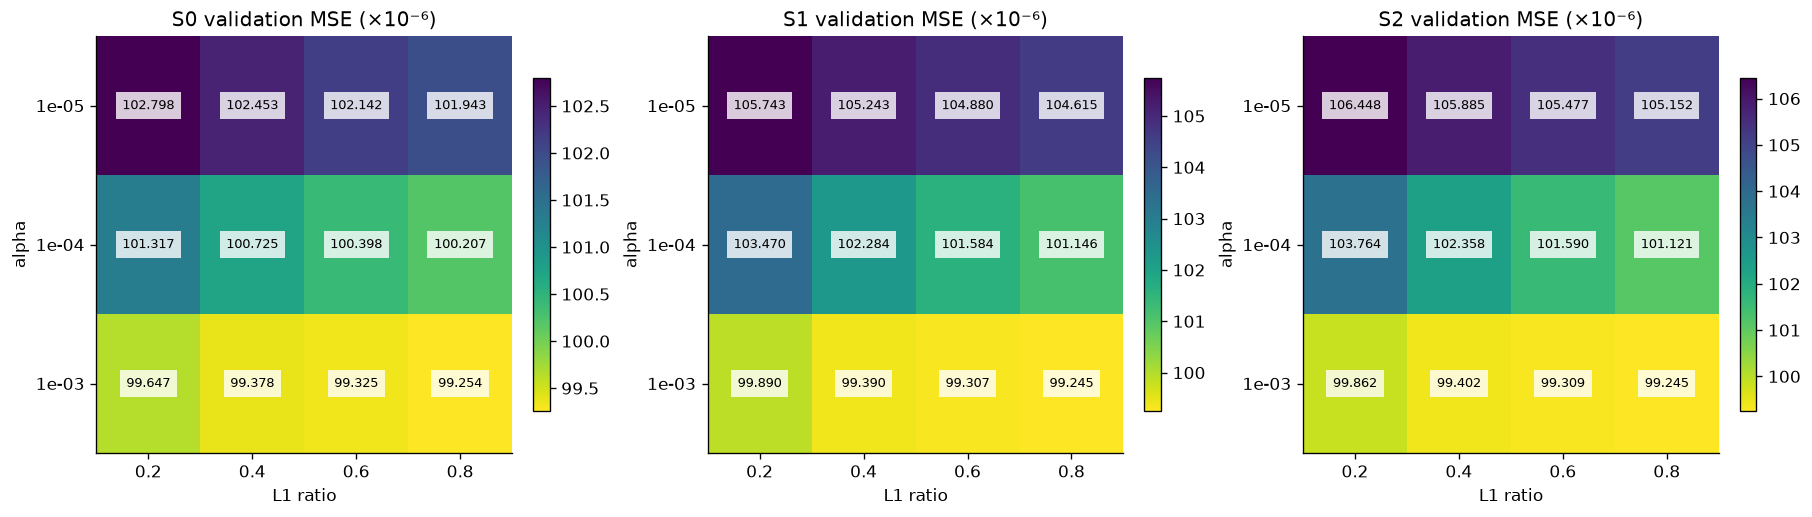

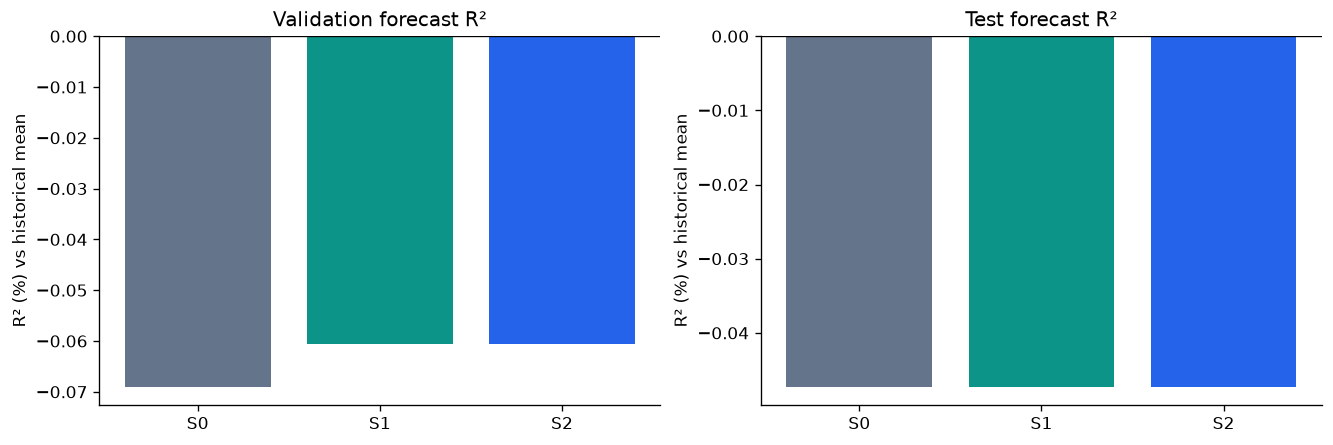

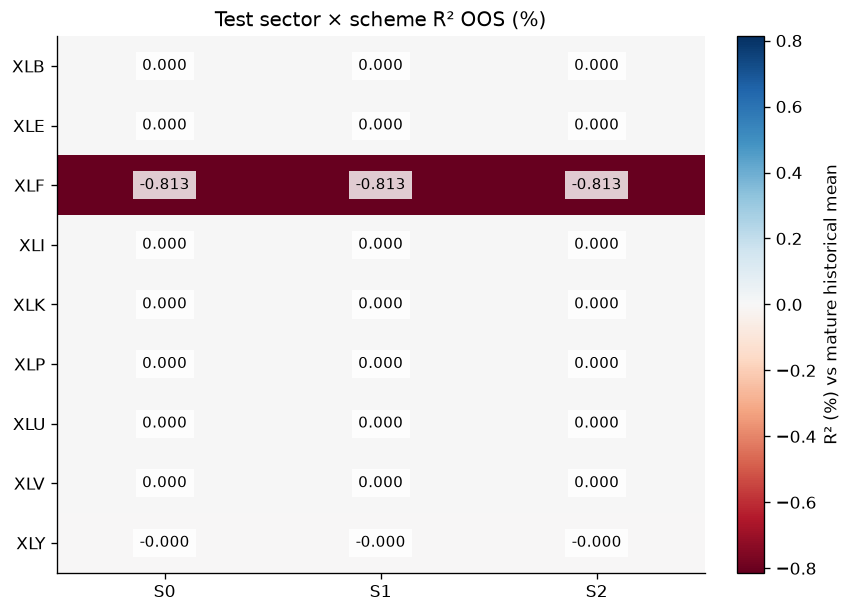

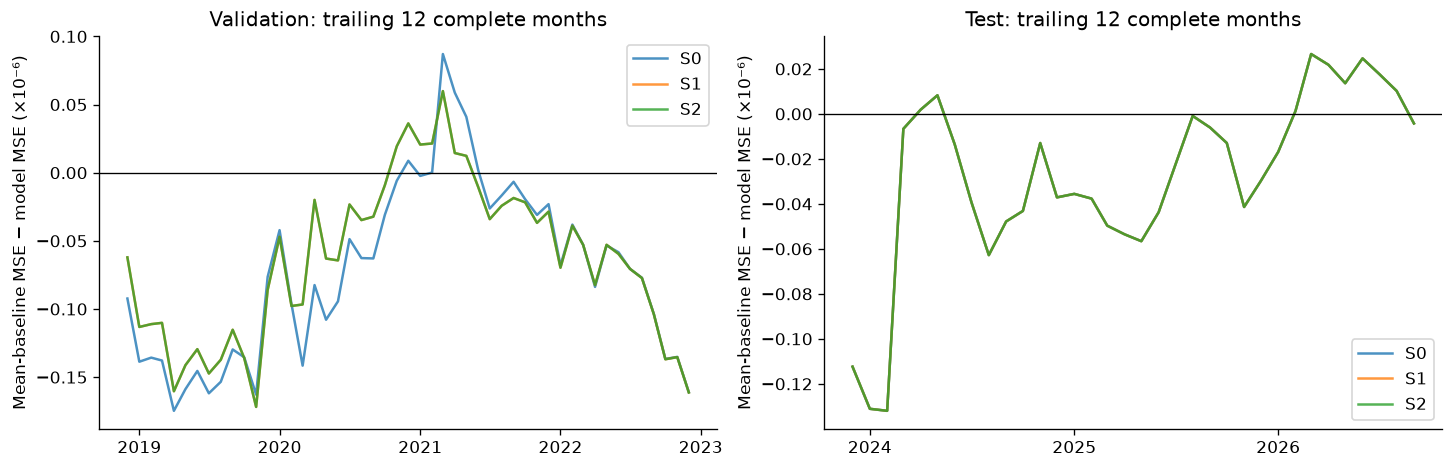

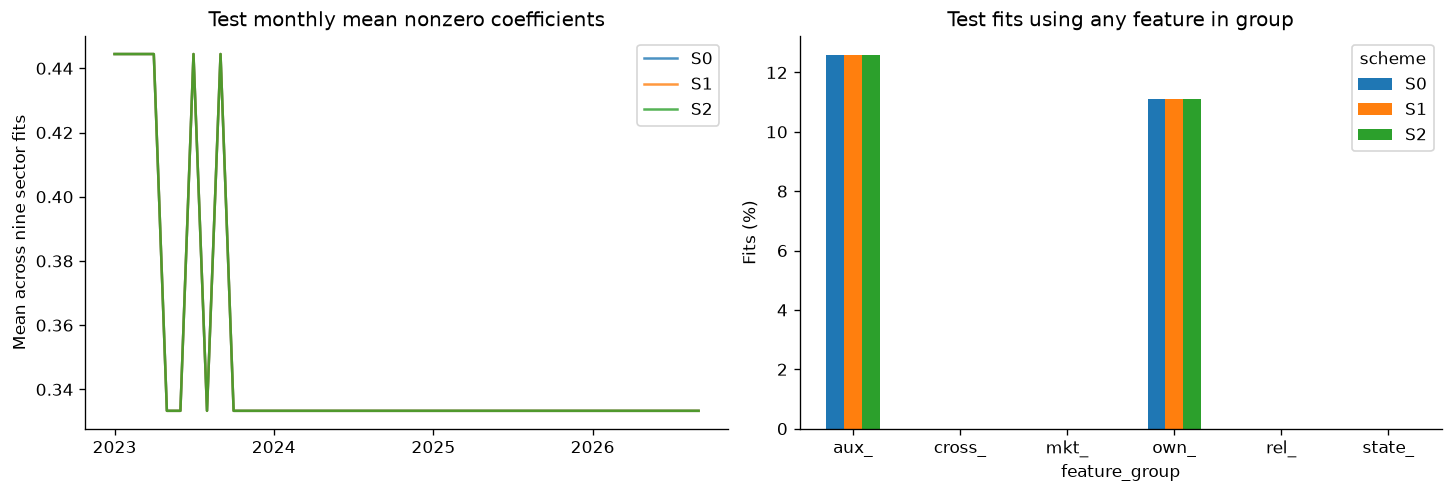

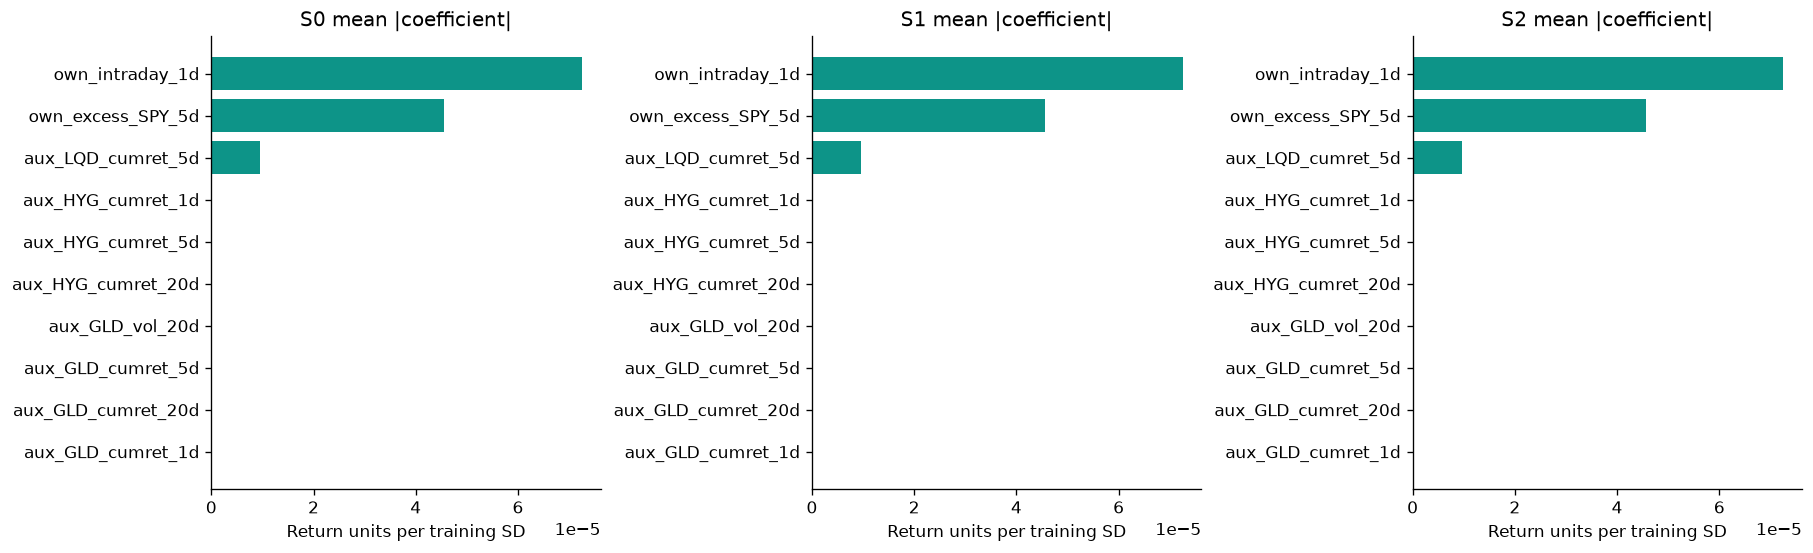

In [10]:
import matplotlib.dates as mdates
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,3,figsize=(15,4.2),constrained_layout=True)
for scheme,ax in zip(SCHEMES,axes):
    grid=search.loc[search.scheme.eq(scheme)].pivot(index='alpha',columns='l1_ratio',values='validation_mse').reindex(index=ALPHAS,columns=L1_RATIOS)*1e6
    im=ax.imshow(grid.to_numpy(),aspect='auto',cmap='viridis_r')
    ax.set(xticks=range(len(L1_RATIOS)),xticklabels=L1_RATIOS,yticks=range(3),yticklabels=[f'{a:.0e}' for a in ALPHAS],
           xlabel='L1 ratio',ylabel='alpha',title=scheme+' validation MSE (×10⁻⁶)')
    for i in range(3):
        for j in range(len(L1_RATIOS)):ax.text(j,i,f'{grid.iloc[i,j]:.3f}',ha='center',va='center',fontsize=8,
            bbox={'facecolor':'white','alpha':.8,'edgecolor':'none'})
    fig.colorbar(im,ax=ax,shrink=.8)
fig.savefig(OUT/'01_validation_grid.png',dpi=180);plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,3.6),constrained_layout=True)
for split,ax in zip(['validation','test'],axes):
    m=forecast_metrics.loc[forecast_metrics['split'].eq(split)].set_index('scheme').reindex(SCHEMES)
    ax.bar(m.index,100*m.R2_OOS_mean,color=['#64748b','#0d9488','#2563eb'])
    ax.axhline(0,color='black',lw=.8);ax.set(title=split.title()+' forecast R²',ylabel='R² (%) vs historical mean')
fig.savefig(OUT/'02_forecast_r2.png',dpi=180);plt.show()

heat=pd.DataFrame(sector_metrics).query("split == 'test'").pivot(index='ticker',columns='scheme',values='R2_OOS_mean').reindex(index=SECTORS,columns=SCHEMES)*100
fig,ax=plt.subplots(figsize=(7,5),constrained_layout=True)
limit=max(float(np.abs(heat.to_numpy()).max()),.01)
im=ax.imshow(heat,aspect='auto',cmap='RdBu',vmin=-limit,vmax=limit)
ax.set(xticks=range(3),xticklabels=SCHEMES,yticks=range(9),yticklabels=SECTORS,title='Test sector × scheme R² OOS (%)')
for i in range(9):
    for j in range(3):ax.text(j,i,f'{heat.iloc[i,j]:.3f}',ha='center',va='center',fontsize=9,
        bbox={'facecolor':'white','alpha':.8,'edgecolor':'none'})
fig.colorbar(im,ax=ax,label='R² (%) vs mature historical mean')
fig.savefig(OUT/'03_sector_r2_heatmap.png',dpi=180);plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,3.8),constrained_layout=True)
for split,ax in zip(['validation','test'],axes):
    for scheme,g in rolling.loc[rolling['split'].eq(split)].groupby('scheme'):
        ax.plot(pd.to_datetime(g.month),g.mse_improvement_mean*1e6,label=scheme,alpha=.8)
    ax.axhline(0,color='black',lw=.8)
    ax.set(title=split.title()+': trailing 12 complete months',ylabel='Mean-baseline MSE − model MSE (×10⁻⁶)')
    ax.legend()
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.savefig(OUT/'04_rolling_loss_improvement.png',dpi=180);plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
monthly_nonzero=test_audit.groupby(['month','scheme']).nonzero.mean().unstack('scheme')
for scheme in SCHEMES:axes[0].plot(pd.to_datetime(monthly_nonzero.index),monthly_nonzero[scheme],label=scheme,alpha=.8)
axes[0].set(title='Test monthly mean nonzero coefficients',ylabel='Mean across nine sector fits');axes[0].legend()
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
group_summary.pivot(index='feature_group',columns='scheme',values='fraction_models_using_group').mul(100).plot.bar(ax=axes[1])
axes[1].set(title='Test fits using any feature in group',ylabel='Fits (%)');axes[1].tick_params(axis='x',rotation=0)
fig.savefig(OUT/'05_sparsity_and_groups.png',dpi=180);plt.show()

fig,axes=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
for scheme,ax in zip(SCHEMES,axes):
    top=coefficient_summary.loc[coefficient_summary.scheme.eq(scheme)].nlargest(10,'mean_absolute_coefficient').sort_values('mean_absolute_coefficient')
    ax.barh(top.feature,top.mean_absolute_coefficient,color='#0d9488')
    ax.set(title=scheme+' mean |coefficient|',xlabel='Return units per training SD')
fig.savefig(OUT/'06_coefficient_stability.png',dpi=180);plt.show()

## 8. Export forecasts and metrics

`elastic_net_predictions.csv` is the clean interface for yae, in the exact order:

`date, ticker, model, scheme, model_month, fit_cutoff, y_hat`

`elastic_net_predictions_full.csv` retains the split, alpha, L1 ratio, target, historical-mean baseline, scoreability and holding timestamps for audit. `y_hat` is a decimal sector-minus-SPY cash-return forecast; `fit_cutoff` is a timezone-aware historical fitting timestamp. Use the shared panel for label availability, execution dates and evaluation eligibility. Do not infer eligibility from the presence of a forecast; the final two dates are intentionally unscored.

All three schemes are handed over. As agreed in the group handoff, yae owns validation selection among entry thresholds, half-threshold exits, at most four pairs, ±12.5% legs, persistent holdings, net SPY exposure and the 3 bp main execution cost. These are interface responsibilities only; this notebook sets no trading thresholds, positions or costs and performs no portfolio evaluation.

Prediction diagnostics describe this model, grid and sample period. Weak or null incremental evidence does not imply that cross-sector information is universally useless. The full group report and video remain separate deliverables.

In [11]:
keys=['date','ticker','model','scheme']
assert not predictions.duplicated(keys).any()
assert set(predictions.scheme)==set(SCHEMES)
assert np.isfinite(predictions.y_hat).all()
assert predictions.groupby(['date','scheme']).ticker.nunique().eq(9).all()
assert (pd.to_datetime(predictions.fit_cutoff,utc=True)
        < pd.to_datetime(predictions.date).dt.tz_localize('America/New_York').dt.tz_convert('UTC')).all()
expected_keys=panel.loc[panel['split'].isin(['validation','test'])&panel.common_features_valid,['date','ticker']]
for scheme in SCHEMES:
    actual_keys=predictions.loc[predictions.scheme.eq(scheme),['date','ticker']].sort_values(['date','ticker']).reset_index(drop=True)
    pd.testing.assert_frame_equal(actual_keys,expected_keys.sort_values(['date','ticker']).reset_index(drop=True))
last_dates=sorted(panel.date.unique())[-2:]
last=predictions.loc[predictions.date.isin(last_dates)]
assert len(last)==2*9*3 and not last.common_scoreable.any()
cols=['date','ticker','model','scheme','model_month','fit_cutoff','y_hat']
predictions_out=predictions.sort_values(['date','ticker','scheme']).reset_index(drop=True)
predictions_out[cols].to_csv(OUT/'elastic_net_predictions.csv',index=False)
predictions_out.to_csv(OUT/'elastic_net_predictions_full.csv',index=False)
restored=pd.read_csv(OUT/'elastic_net_predictions.csv',parse_dates=['date'],float_precision='round_trip')
assert list(restored.columns)==cols and len(restored)==len(predictions_out)
np.testing.assert_array_equal(restored.y_hat.to_numpy(),predictions_out.y_hat.to_numpy())
assert all(sha(ROOT/p)==h for p,h in source_hashes.items()), 'An upstream input changed'

fm=forecast_metrics.loc[forecast_metrics['split'].eq('test')].set_index('scheme')
wide=predictions.loc[predictions['split'].eq('test')].pivot(index=['date','ticker'],columns='scheme',values='y_hat')
identical=bool(wide.S0.eq(wide.S1).all() and wide.S1.eq(wide.S2).all())
cross_groups=group_summary.loc[group_summary.feature_group.isin(['cross_','rel_'])]
parameter_description='; '.join(f'{r.scheme}: alpha={r.alpha:g}, rho={r.l1_ratio:g}' for r in selected.itertuples())
incremental_description = ('Test forecasts coincide across S0/S1/S2 under the validation-selected models.' if identical else 'Test forecasts differ across schemes; assess incremental prediction accuracy using the paired loss differences and uncertainty table.')
summary=f"""
### Elastic Net results and interpretation

- All three pre-specified schemes are retained; there is no overall winner. The common search uses rho ∈ {L1_RATIOS} and alpha ∈ {ALPHAS}. Validation-selected parameters: {parameter_description}.
- Validation-selected MSEs lie within {selected.validation_mse.max()-selected.validation_mse.min():.3g} overall; the S1–S2 MSE gap is {abs(selected.set_index('scheme').loc['S1','validation_mse']-selected.set_index('scheme').loc['S2','validation_mse']):.3g}. Interpret very small MSE differences with the paired losses and numerical precision in mind.
- Test R² vs mature historical mean: S0 {fm.loc['S0','R2_OOS_mean']:.3%}, S1 {fm.loc['S1','R2_OOS_mean']:.3%}, S2 {fm.loc['S2','R2_OOS_mean']:.3%}. Test forecasts are exactly identical across all schemes: **{identical}** (including the final unscored dates).
- Locked test fits have mean nonzero coefficient count {test_audit.nonzero.mean():.3f}, median {test_audit.nonzero.median():.0f}, range {test_audit.nonzero.min()}–{test_audit.nonzero.max()}; {test_audit.nonzero.eq(0).mean():.2%} are intercept-only. Extra cross-sector/relationship feature selection rate is {cross_groups.selection_rate.max():.2%} at most across the relevant groups.
- For sector-level interpretation, see Section 10 (XLF concentration diagnostic), which reports coefficient-selection concentration, sector-level test losses and XLF's validation performance across training windows. These descriptive checks do not retune the locked test model.
- The validation-selected pair (alpha=1e-3, rho=0.8) is the upper corner of the pre-specified grid for every scheme, and {test_audit.nonzero.eq(0).mean():.2%} of locked test fits are intercept-only. The grid was fixed before any forecast was generated and is not revised after observing test results. The forecasts should therefore be read as close to the historical-mean forecast, and the absence of cross-sector coefficients is a statement about this grid, not about cross-sector information in general.
- {incremental_description} This is a result about this design and period, not a general claim that cross-sector effects never exist. Sector, rolling-loss, coefficient and uncertainty diagnostics are descriptive and are not used to retune the model.
- All 945 monthly-sector eligibility records match upstream. Final checks confirm unique forecasts, all three schemes, nine sectors per signal date, finite predictions, mature training labels, complete eligible key coverage and all 54 terminal unscored forecasts.
- Deliver the clean seven-column forecasts and full audit file to yae for unified validation/backtesting. No independently specified portfolio metrics are part of this contribution.
"""
display(Markdown(summary))
(OUT/'report_summary.md').write_text(summary+'\n')
manifest=dict(completed_utc=datetime.now(timezone.utc).isoformat(),
    python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,
    scikit_learn=sklearn.__version__,source_hashes=source_hashes,selected=lock,
    validation_fits=int(audit['split'].eq('validation').sum()),test_fits=len(test_audit),
    prediction_rows=len(predictions_out),terminal_unscored_rows=len(last),
    eligibility_records_crosschecked=len(eligibility),
    scope='Elastic Net forecasting and prediction diagnostics only',
    reproduction_provenance=config['reproduction_provenance'],
    l1_ratios=L1_RATIOS,
    checks=['unique keys','predictor whitelist','finite eligible inputs','mature training labels',
            'future forecast timestamps','identical scoring samples','upstream monthly eligibility',
            'nine sectors per date/scheme','all eligible keys','terminal forecasts retained',
            'export schema and exact forecast roundtrip','upstream hashes unchanged'])
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
print('All forecasting integrity checks passed. Clean export rows:',len(predictions_out))


### Elastic Net results and interpretation

- All three pre-specified schemes are retained; there is no overall winner. The common search uses rho ∈ [0.2, 0.4, 0.6, 0.8] and alpha ∈ [1e-05, 0.0001, 0.001]. Validation-selected parameters: S0: alpha=0.001, rho=0.8; S1: alpha=0.001, rho=0.8; S2: alpha=0.001, rho=0.8.
- Validation-selected MSEs lie within 8.48e-09 overall; the S1–S2 MSE gap is 2.03e-19. Interpret very small MSE differences with the paired losses and numerical precision in mind.
- Test R² vs mature historical mean: S0 -0.047%, S1 -0.047%, S2 -0.047%. Test forecasts are exactly identical across all schemes: **True** (including the final unscored dates).
- Locked test fits have mean nonzero coefficient count 0.348, median 0, range 0–3; 87.41% are intercept-only. Extra cross-sector/relationship feature selection rate is 0.00% at most across the relevant groups.
- For sector-level interpretation, see Section 10 (XLF concentration diagnostic), which reports coefficient-selection concentration, sector-level test losses and XLF's validation performance across training windows. These descriptive checks do not retune the locked test model.
- The validation-selected pair (alpha=1e-3, rho=0.8) is the upper corner of the pre-specified grid for every scheme, and 87.41% of locked test fits are intercept-only. The grid was fixed before any forecast was generated and is not revised after observing test results. The forecasts should therefore be read as close to the historical-mean forecast, and the absence of cross-sector coefficients is a statement about this grid, not about cross-sector information in general.
- Test forecasts coincide across S0/S1/S2 under the validation-selected models. This is a result about this design and period, not a general claim that cross-sector effects never exist. Sector, rolling-loss, coefficient and uncertainty diagnostics are descriptive and are not used to retune the model.
- All 945 monthly-sector eligibility records match upstream. Final checks confirm unique forecasts, all three schemes, nine sectors per signal date, finite predictions, mature training labels, complete eligible key coverage and all 54 terminal unscored forecasts.
- Deliver the clean seven-column forecasts and full audit file to yae for unified validation/backtesting. No independently specified portfolio metrics are part of this contribution.


All forecasting integrity checks passed. Clean export rows: 59346


## 9. Validation diagnostics: regularization, windows and sector heterogeneity

Compare Elastic Net under expanding, 5-year rolling and 3-year rolling training windows, plus a Ridge benchmark, on the 2018–2022 validation period. Also check sector-equal-weight evaluation, sparsity and year-by-year stability.

Elastic Net uses the same grid as the main pipeline: $\rho \in \{0.2,0.4,0.6,0.8\}$ and $\alpha \in \{10^{-5},10^{-4},10^{-3}\}$, i.e. 12 parameter pairs for every window and scheme. Ridge minimizes MSE/2 + λ‖β‖²/2 with λ ∈ {0.01, 0.1, 1, 10} (sklearn alpha = n_train × λ). Three windows × three schemes give 144 candidate configurations and 77,760 monthly-sector fits, of which 58,320 are Elastic Net and 19,440 are Ridge.

All models use only labels that were already mature at the time, and StandardScaler is fit on that fit’s training sample only. Cross-window comparisons use the same expanding historical mean as the baseline; each window’s own historical mean is also reported. Rolling windows require at least 252 eligible observations; this checks feasibility only and is not used for tuning. Windows are always cut by calendar year.

This section compares validation results only and does not re-select the test model. The best validation result carries selection bias, and the annual and sector analyses are descriptive diagnostics. Outputs are saved in `results/elastic_net/exploratory_validation/`.

The Ridge closed-form solution is cross-checked against sklearn Ridge for the first validation month and first sector, for every window, scheme and λ (36 checks in total; rtol=1e-8, atol=1e-11).

In [12]:
# Validation environment check
from pathlib import Path
import sys
print('Python:', sys.version.split()[0])

Python: 3.12.10


In [13]:
# 9.1 Validation-only setup; share the main Elastic Net parameter grid.
import json, hashlib, platform, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

EV_ROOT = Path.cwd().resolve()
if not (EV_ROOT / 'data/processed/panel_spec.json').exists():
    EV_ROOT = EV_ROOT.parent
assert (EV_ROOT / 'data/processed/panel_spec.json').exists()
EV_OUT = EV_ROOT / 'results/elastic_net/exploratory_validation'
EV_OUT.mkdir(parents=True, exist_ok=True)
EV_SPEC = json.loads((EV_ROOT / 'data/processed/panel_spec.json').read_text())
EV_SECTORS = sorted(EV_SPEC['input_files'])
EV_SCHEMES = ['S0', 'S1', 'S2']
EV_ALPHAS = ALPHAS.copy()
EV_L1_RATIOS = L1_RATIOS.copy()
assert EV_L1_RATIOS == [0.2, 0.4, 0.6, 0.8]
EV_GRID = [(a, r) for a in EV_ALPHAS for r in EV_L1_RATIOS]
EV_LAMBDAS = [0.01, 0.1, 1.0, 10.0]
EV_WINDOWS = {'expanding': None, 'rolling_5y': 5, 'rolling_3y': 3}
EV_CANDIDATES = [dict(family='ElasticNet', parameter=f'a={a:g},r={r:g}', alpha=a, ratio=r, ridge_lambda=None) for a,r in EV_GRID]
EV_CANDIDATES += [dict(family='Ridge', parameter=f'lambda={v:g}', alpha=None, ratio=None, ridge_lambda=v) for v in EV_LAMBDAS]
ev_panel = pd.read_csv(EV_ROOT / EV_SPEC['shared_panel'], parse_dates=['date'], float_precision='round_trip')
for ev_col in ['signal_at', 'label_available_at']:
    ev_panel[ev_col] = pd.to_datetime(ev_panel[ev_col], utc=True)
# Remove all test rows before any training/evaluation work.
ev_panel = ev_panel.loc[ev_panel.date.lt('2023-01-01')].copy()
assert not ev_panel.duplicated(['date','ticker']).any()
ev_calendar = pd.DatetimeIndex(sorted(ev_panel.date.unique()))
ev_data = {}
ev_sources = [EV_ROOT/'data/processed/panel_spec.json', EV_ROOT/EV_SPEC['shared_panel']]
for ev_ticker in EV_SECTORS:
    ev_info = ev_panel.loc[ev_panel.ticker.eq(ev_ticker)].sort_values('date').reset_index(drop=True)
    ev_xs = {}
    for ev_scheme in EV_SCHEMES:
        ev_path = EV_ROOT / EV_SPEC['input_files'][ev_ticker][ev_scheme]
        ev_sources.append(ev_path)
        ev_f = pd.read_csv(ev_path, parse_dates=['date'], float_precision='round_trip')
        ev_f = ev_f.loc[ev_f.date.lt('2023-01-01')].reset_index(drop=True)
        ev_cols = EV_SPEC['predictors_by_target'][ev_ticker][ev_scheme]
        assert list(ev_f.columns) == ['date','ticker'] + ev_cols
        pd.testing.assert_frame_equal(ev_f[['date','ticker']], ev_info[['date','ticker']])
        assert not set(ev_cols).intersection(EV_SPEC['columns_not_predictors'])
        ev_xs[ev_scheme] = ev_f[ev_cols].to_numpy(float)
        assert np.isfinite(ev_xs[ev_scheme][ev_info.common_features_valid]).all()
    ev_data[ev_ticker] = (ev_info, ev_xs)
ev_original_files = list((EV_ROOT/'results/elastic_net').glob('*'))
ev_original_hashes = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in ev_original_files if p.is_file()}
ev_config = dict(scope='validation diagnostics: regularization and training windows', validation='2018-2022',
    windows=EV_WINDOWS, elastic_net_grid=EV_GRID, ridge_lambdas=EV_LAMBDAS,
    ridge_objective='SSE/(2*n) + lambda*||beta||^2/2; intercept unpenalized',
    elastic_net_l1_ratios=EV_L1_RATIOS, elastic_net_alphas=EV_ALPHAS,
    candidates_per_scheme=48, total_candidates=144, monthly_fits=77760,
    primary_selection='pooled validation MSE within family/window/scheme',
    sensitivity_selection='mean of sector MSE / common expanding-mean baseline MSE',
    common_baseline='mature expanding historical mean for every window',
    tie_rule='larger penalty then larger l1_ratio',
    seed=5205, python=platform.python_version(), sklearn=sklearn.__version__,
    source_hashes={str(p.relative_to(EV_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in ev_sources})
(EV_OUT/'exploration_config.json').write_text(json.dumps(ev_config, indent=2)+'\n')
print('Validation-only setup ready: 144 candidates, 60 months, 9 sectors; no test forecasts.')
print('Outputs:', EV_OUT.relative_to(EV_ROOT))

Validation-only setup ready: 144 candidates, 60 months, 9 sectors; no test forecasts.
Outputs: results/elastic_net/exploratory_validation


In [14]:
# 9.2 Monthly forward validation. All candidate fits use identical scored rows.
# Minimum 252 eligible observations; upstream exclusions leave as few as 498 in 3y windows.
# Numerical retries only: up to 1,000,000 iterations; unchanged objective/tolerance.
from sklearn.linear_model import Ridge
def ev_fit_en(X, y, alpha, ratio):
    for use_gram, limit in [(True, 10000), (True, 100000), (True, 1000000)]:
        m = ElasticNet(alpha=alpha, l1_ratio=ratio, fit_intercept=True,
                       max_iter=limit, tol=1e-6, selection='cyclic',
                       precompute=use_gram, random_state=5205)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            m.fit(X, y)
        if not any(issubclass(w.category, ConvergenceWarning) for w in caught):
            return m, limit
    raise RuntimeError(f'Unconverged fit: n={len(y)}, alpha={alpha}, ratio={ratio}; last warning={[str(w.message) for w in caught]}')

def ev_run_validation():
    rows, coefs = [], []
    started = time.perf_counter()
    with threadpool_limits(limits=1):
        for mi, month in enumerate(pd.period_range('2018-01','2022-12',freq='M')):
            dates = ev_calendar[ev_calendar.to_period('M') == month]
            prior = ev_calendar[ev_calendar.get_loc(dates[0])-1]
            cutoff = (prior + pd.Timedelta(hours=18)).tz_localize('America/New_York').tz_convert('UTC')
            for ticker in EV_SECTORS:
                info, xs = ev_data[ticker]
                mature = (info.date.ge('2008-01-01') & info.common_features_valid & info.label_valid
                          & info.signal_at.le(cutoff) & info.label_available_at.le(cutoff)).to_numpy()
                pred = (info.date.dt.to_period('M').eq(month) & info['split'].eq('validation')
                        & info.common_scoreable).to_numpy()
                assert pred.any() and (info.loc[pred,'signal_at'] > cutoff).all()
                assert (info.loc[pred,'date'] < pd.Timestamp('2023-01-01')).all()
                ypred = info.loc[pred,'target_relative_return'].to_numpy(float)
                common_mean = info.loc[mature,'target_relative_return'].mean()
                base_sse = float(np.square(ypred-common_mean).sum())
                key_hash = hashlib.sha256(info.loc[pred,['date','ticker']].to_csv(index=False).encode()).hexdigest()
                for window, years in EV_WINDOWS.items():
                    train = mature.copy()
                    if years is not None:
                        train &= info.date.ge(month.start_time-pd.DateOffset(years=years)).to_numpy()
                    assert train.sum() >= 252, f'Insufficient eligible history: {month}/{ticker}/{window}'
                    assert info.loc[train,'label_available_at'].max() <= cutoff
                    y = info.loc[train,'target_relative_return'].to_numpy(float)
                    assert np.isfinite(y).all() and np.isfinite(ypred).all()
                    own_sse = float(np.square(ypred-y.mean()).sum())
                    for scheme in EV_SCHEMES:
                        scaler = StandardScaler()
                        X = np.asfortranarray(scaler.fit_transform(xs[scheme][train]))
                        XP = scaler.transform(xs[scheme][pred])
                        # Ridge closed-form solve via one shared eigendecomposition.
                        xm = X.mean(axis=0)
                        XC = X-xm
                        gram = XC.T @ XC / len(y)
                        rhs = XC.T @ (y-y.mean()) / len(y)
                        eig, vec = np.linalg.eigh(gram)
                        projected = vec.T @ rhs
                        for cand in EV_CANDIDATES:
                            if cand['family'] == 'ElasticNet':
                                model, max_iter_used = ev_fit_en(X, y, cand['alpha'], cand['ratio'])
                                convergence_retry_count = [10000,100000,1000000].index(max_iter_used)
                                coef = model.coef_.copy()
                                intercept = float(model.intercept_)
                                iterations, gap = int(model.n_iter_), float(model.dual_gap_)
                                alpha_max = float(np.max(np.abs(rhs))/cand['ratio'])
                                alpha_fraction = cand['alpha']/alpha_max if alpha_max else np.inf
                            else:
                                coef = vec @ (projected/(np.maximum(eig,0)+cand['ridge_lambda']))
                                intercept = float(y.mean()-xm @ coef)
                                iterations, gap, alpha_fraction = 0, 0.0, np.nan
                                max_iter_used, convergence_retry_count = None, None
                                if mi == 0 and ticker == EV_SECTORS[0]:
                                    reference = Ridge(alpha=len(y)*cand['ridge_lambda'],solver='cholesky').fit(X,y)
                                    np.testing.assert_allclose(XP@coef+intercept,reference.predict(XP),rtol=1e-8,atol=1e-11)
                            p = XP @ coef + intercept
                            assert np.isfinite(p).all()
                            # One fit-level coefficient vector, aligned to its metric row.
                            coefs.append(coef)
                            rows.append(dict(month=str(month), year=month.year, ticker=ticker,
                                scheme=scheme, window=window, **cand, n=int(pred.sum()),
                                sse=float(np.square(ypred-p).sum()), sae=float(np.abs(ypred-p).sum()),
                                base_sse=base_sse, own_mean_sse=own_sse,
                                zero_sse=float(np.square(ypred).sum()),
                                sign_correct=int((np.sign(p)==np.sign(ypred)).sum()),
                                training_rows=int(train.sum()), fit_cutoff=str(cutoff),
                                latest_label=str(info.loc[train,'label_available_at'].max()),
                                score_keys_sha256=key_hash, nonzero=int((np.abs(coef)>1e-12).sum()),
                                l1_norm=float(np.abs(coef).sum()), n_iter=iterations, dual_gap=gap,
                                max_iter_used=max_iter_used, convergence_retry_count=convergence_retry_count,
                                alpha_over_alpha_max=alpha_fraction))
            if (mi+1)%6 == 0:
                print(f'Validation {month}: {mi+1}/60 months; {len(rows):,} fits; {time.perf_counter()-started:.1f}s',flush=True)
    result = pd.DataFrame(rows)
    for field in ['max_iter_used','convergence_retry_count']:
        result[field] = pd.array(result[field],dtype="Int64")
    assert len(result) == 77760
    assert result.groupby(['month','ticker']).score_keys_sha256.nunique().eq(1).all()
    assert (pd.to_datetime(result.latest_label,utc=True) <= pd.to_datetime(result.fit_cutoff,utc=True)).all()
    result.to_csv(EV_OUT/'monthly_validation_metrics_and_audit.csv',index=False)
    return result, coefs

ev_monthly, ev_coef_vectors = ev_run_validation()
print('All 77,760 fits completed. Matched scored keys and mature-label checks passed.')


# Iteration budgets apply only to Elastic Net; closed-form Ridge has no max_iter.
ev_en_audit = ev_monthly.loc[ev_monthly.family.eq('ElasticNet')]
assert ev_en_audit.max_iter_used.notna().all()
assert ev_en_audit.convergence_retry_count.notna().all()
assert ev_monthly.loc[ev_monthly.family.eq('Ridge'),'max_iter_used'].isna().all()
assert (ev_en_audit.n_iter <= ev_en_audit.max_iter_used).all()
ev_convergence_summary = ev_en_audit.max_iter_used.value_counts().reindex(
    [10000,100000,1000000],fill_value=0).rename_axis('max_iter_used').rename('number_of_fits').reset_index()
assert int(ev_convergence_summary.number_of_fits.sum()) == len(ev_en_audit) == 58320
ev_convergence_summary.to_csv(EV_OUT/'elastic_net_convergence_summary.csv',index=False)
display(Markdown('### Elastic Net convergence budgets (58,320 fits; Ridge excluded)'))
display(ev_convergence_summary)
print('Ridge closed-form fits:', int(ev_monthly.family.eq('Ridge').sum()), '; max_iter_used is not applicable.')

Validation 2018-06: 6/60 months; 7,776 fits; 24.6s
Validation 2018-12: 12/60 months; 15,552 fits; 50.6s
Validation 2019-06: 18/60 months; 23,328 fits; 72.9s
Validation 2019-12: 24/60 months; 31,104 fits; 91.6s
Validation 2020-06: 30/60 months; 38,880 fits; 146.5s
Validation 2020-12: 36/60 months; 46,656 fits; 218.1s
Validation 2021-06: 42/60 months; 54,432 fits; 269.8s
Validation 2021-12: 48/60 months; 62,208 fits; 318.1s
Validation 2022-06: 54/60 months; 69,984 fits; 369.2s
Validation 2022-12: 60/60 months; 77,760 fits; 416.5s
All 77,760 fits completed. Matched scored keys and mature-label checks passed.


### Elastic Net convergence budgets (58,320 fits; Ridge excluded)

,max_iter_used,number_of_fits
0,10000,53160
1,100000,4949
2,1000000,211


Ridge closed-form fits: 19440 ; max_iter_used is not applicable.


In [15]:
# 9.3 Compare selection rules, years, sectors and validation sparsity.
EV_KEYS = ['scheme','family','window','parameter']
ev_sumcols = ['n','sse','sae','base_sse','own_mean_sse','zero_sse','sign_correct']
def ev_aggregate(frame, keys):
    z = frame.groupby(keys,as_index=False)[ev_sumcols].sum()
    z['MSE'] = z.sse/z.n
    z['RMSE_bp'] = np.sqrt(z.MSE)*10000
    z['MAE_bp'] = z.sae/z.n*10000
    z['R2_common_mean'] = 1-z.sse/z.base_sse
    z['R2_window_mean'] = 1-z.sse/z.own_mean_sse
    z['R2_zero'] = 1-z.sse/z.zero_sse
    z['direction_accuracy'] = z.sign_correct/z.n
    return z

ev_sector_grid = ev_aggregate(ev_monthly, EV_KEYS+['ticker'])
ev_grid = ev_aggregate(ev_monthly, EV_KEYS)
ev_sector_grid['normalized_MSE'] = ev_sector_grid.sse/ev_sector_grid.base_sse
ev_balanced = ev_sector_grid.groupby(EV_KEYS,as_index=False).normalized_MSE.mean()
ev_grid = ev_grid.merge(ev_balanced,on=EV_KEYS,validate='one_to_one')
ev_sparsity = ev_monthly.groupby(EV_KEYS,as_index=False).agg(
    mean_nonzero=('nonzero','mean'), intercept_only_fraction=('nonzero',lambda x:float(x.eq(0).mean())))
ev_grid = ev_grid.merge(ev_sparsity,on=EV_KEYS,validate='one_to_one')
ev_meta = pd.DataFrame(EV_CANDIDATES)
ev_grid = ev_grid.merge(ev_meta,on=['family','parameter'],validate='many_to_one')
ev_grid['penalty_order'] = ev_grid.alpha.fillna(ev_grid.ridge_lambda)
ev_grid['ratio_order'] = ev_grid.ratio.fillna(0)
assert len(ev_grid)==144 and ev_grid.n.nunique()==1
assert int(ev_grid.n.iloc[0]) == int(ev_panel.loc[ev_panel['split'].eq('validation'),'common_scoreable'].sum())
ev_grid.to_csv(EV_OUT/'all_144_validation_candidates.csv',index=False)
ev_sector_grid.to_csv(EV_OUT/'all_candidates_by_sector.csv',index=False)

# Main expanding-grid reproduction check using validation scores only.
ev_old_path = EV_ROOT/'results/elastic_net/validation_grid.csv'
if ev_old_path.exists():
    ev_old = pd.read_csv(ev_old_path)
    ev_reproduced = ev_grid.query("family == 'ElasticNet' and window == 'expanding'").merge(
        ev_old,on=['scheme','alpha'],suffixes=('','_old'))
    ev_reproduced = ev_reproduced.loc[np.isclose(ev_reproduced.ratio,ev_reproduced.l1_ratio)]
    assert len(ev_reproduced)==36
    np.testing.assert_allclose(ev_reproduced.MSE,ev_reproduced.validation_mse,rtol=1e-8,atol=1e-14)
    print('All 36 main-grid validation scores reproduced within numerical tolerance.')

ev_choice_parts = []
for ev_rule, ev_score in [('pooled_MSE','MSE'),('sector_equal','normalized_MSE')]:
    ev_part = ev_grid.sort_values([ev_score,'penalty_order','ratio_order'],ascending=[True,False,False]).groupby(
        ['scheme','family','window'],sort=False).head(1).copy()
    ev_part['selection_rule'] = ev_rule
    ev_choice_parts.append(ev_part)
ev_choices = pd.concat(ev_choice_parts,ignore_index=True)
ev_choices.to_csv(EV_OUT/'validation_selected_comparisons.csv',index=False)
ev_unique_choices = ev_choices[EV_KEYS].drop_duplicates()
ev_selected_months = ev_monthly.merge(ev_unique_choices,on=EV_KEYS,validate='many_to_one')
ev_annual = ev_aggregate(ev_selected_months,EV_KEYS+['year'])
ev_annual.to_csv(EV_OUT/'selected_annual_metrics.csv',index=False)
ev_selected_sectors = ev_sector_grid.merge(ev_unique_choices,on=EV_KEYS,validate='many_to_one')
ev_selected_sectors.to_csv(EV_OUT/'selected_sector_metrics.csv',index=False)

# Counterfactual sector-wise best parameter: diagnostic only, never a deployed selection.
ev_sector_best = ev_sector_grid.sort_values('MSE').groupby(['scheme','family','window','ticker'],sort=False).head(1)
ev_sector_best.to_csv(EV_OUT/'sector_parameter_preferences_diagnostic_only.csv',index=False)

# Feature frequencies include every month, including intercept-only fits.
ev_feature_rows, ev_group_rows = [], []
ev_chosen_set = set(ev_unique_choices.itertuples(index=False,name=None))
for ev_key, ev_g in ev_monthly.groupby(EV_KEYS+['ticker'],sort=False):
    if ev_key[:4] not in ev_chosen_set:
        continue
    ev_scheme, ev_family, ev_window, ev_parameter, ev_ticker = ev_key
    ev_names = EV_SPEC['predictors_by_target'][ev_ticker][ev_scheme]
    ev_B = np.stack([ev_coef_vectors[i] for i in ev_g.index])
    assert ev_B.shape == (60,len(ev_names))
    ev_used = np.abs(ev_B)>1e-12
    ev_ident = dict(zip(EV_KEYS+['ticker'],ev_key))
    for j, name in enumerate(ev_names):
        ev_feature_rows.append(dict(**ev_ident,feature=name,selection_rate=float(ev_used[:,j].mean()),
            mean_coefficient=float(ev_B[:,j].mean()),mean_abs_coefficient=float(np.abs(ev_B[:,j]).mean()),
            coefficient_sd=float(ev_B[:,j].std()),months=60))
    for group in ['own_','mkt_','aux_','state_','cross_','rel_']:
        mask = np.array([f.startswith(group) for f in ev_names])
        if mask.any():
            ev_group_rows.append(dict(**ev_ident,feature_group=group,
                fraction_fits_using_group=float(ev_used[:,mask].any(axis=1).mean()),
                feature_selection_rate=float(ev_used[:,mask].mean())))
ev_features = pd.DataFrame(ev_feature_rows)
ev_groups = pd.DataFrame(ev_group_rows)
ev_features.to_csv(EV_OUT/'selected_validation_feature_stability.csv',index=False)
ev_groups.to_csv(EV_OUT/'selected_validation_feature_groups.csv',index=False)

display(Markdown('### Validation comparisons (exploratory; selected on these same dates)'))
display(ev_choices[['selection_rule','scheme','family','window','parameter','RMSE_bp',
    'R2_common_mean','normalized_MSE','mean_nonzero','intercept_only_fraction']].round(6))
print('Positive R2_common_mean = improvement over the SAME expanding-mean baseline.')
print('Ridge generally has dense coefficients; its nonzero count is not a variable-selection claim.')

All 36 main-grid validation scores reproduced within numerical tolerance.


### Validation comparisons (exploratory; selected on these same dates)

,selection_rule,scheme,family,window,parameter,RMSE_bp,R2_common_mean,normalized_MSE,mean_nonzero,intercept_only_fraction
0,pooled_MSE,S2,Ridge,expanding,lambda=10,99.526719,0.001307,0.998400,102.000000,0.000000
1,pooled_MSE,S1,Ridge,expanding,lambda=10,99.527645,0.001288,0.998422,97.000000,0.000000
2,pooled_MSE,S0,Ridge,expanding,lambda=10,99.535369,0.001133,0.998558,57.000000,0.000000
3,pooled_MSE,S0,Ridge,rolling_5y,lambda=10,99.606937,-0.000304,1.000058,57.000000,0.000000
4,pooled_MSE,S1,Ridge,rolling_5y,lambda=10,99.611103,-0.000387,1.000416,97.000000,0.000000
5,pooled_MSE,S2,Ridge,rolling_5y,lambda=10,99.611420,-0.000394,1.000503,102.000000,0.000000
6,pooled_MSE,S2,ElasticNet,expanding,"a=0.001,r=0.8",99.621955,-0.000605,1.000692,0.755556,0.677778
7,pooled_MSE,S1,ElasticNet,expanding,"a=0.001,r=0.8",99.621955,-0.000605,1.000692,0.755556,0.677778
8,pooled_MSE,S0,ElasticNet,expanding,"a=0.001,r=0.8",99.626212,-0.000691,1.000795,0.557407,0.724074
9,pooled_MSE,S0,Ridge,rolling_3y,lambda=10,99.639257,-0.000953,1.000830,57.000000,0.000000


Positive R2_common_mean = improvement over the SAME expanding-mean baseline.
Ridge generally has dense coefficients; its nonzero count is not a variable-selection claim.


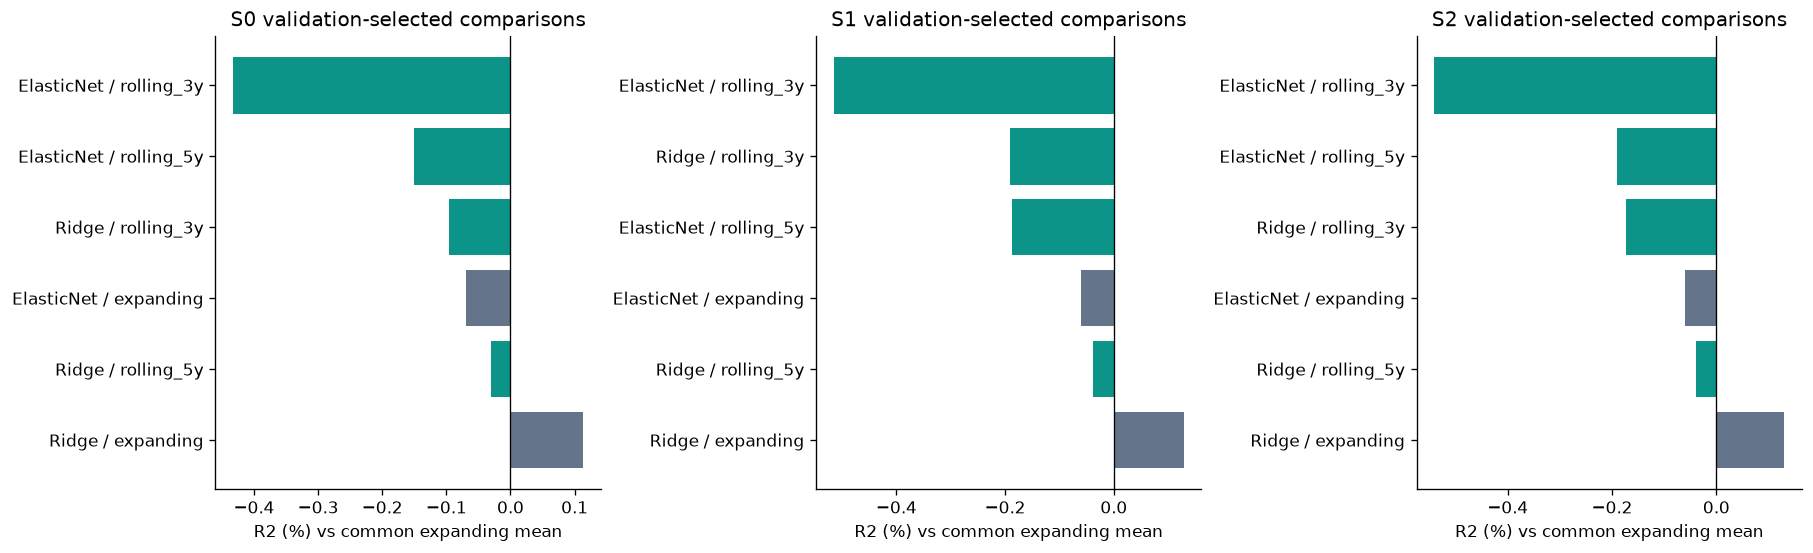

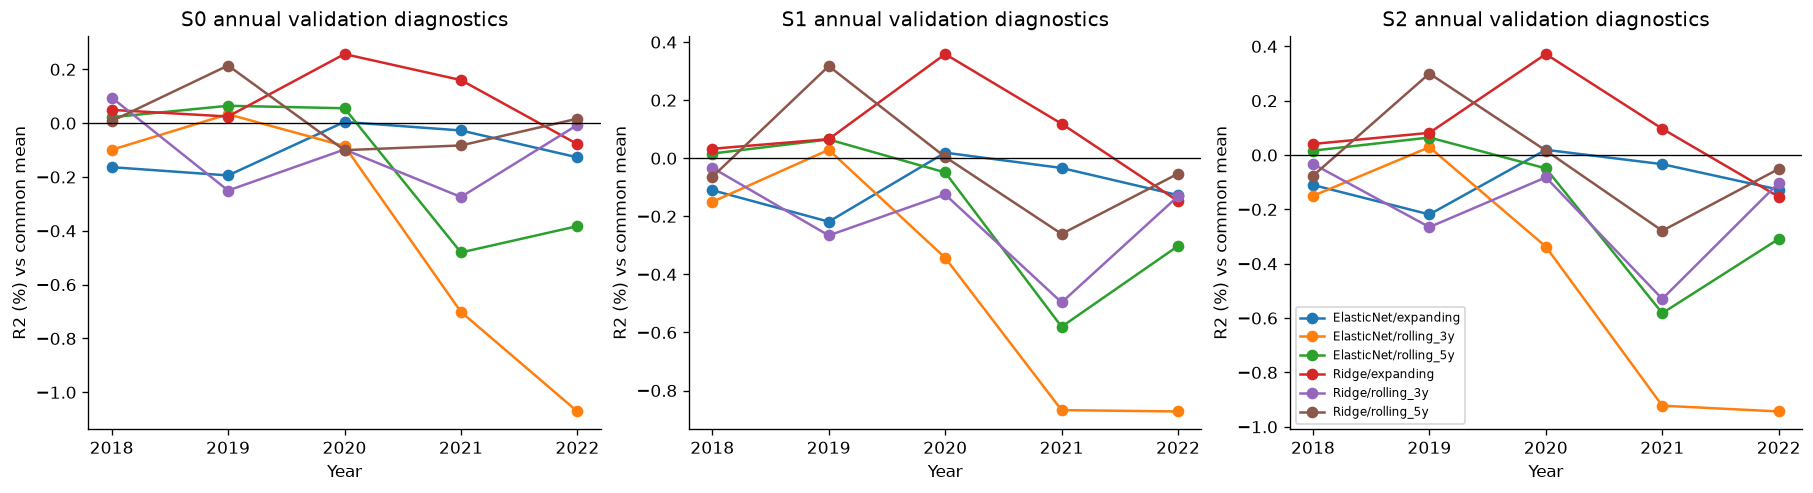

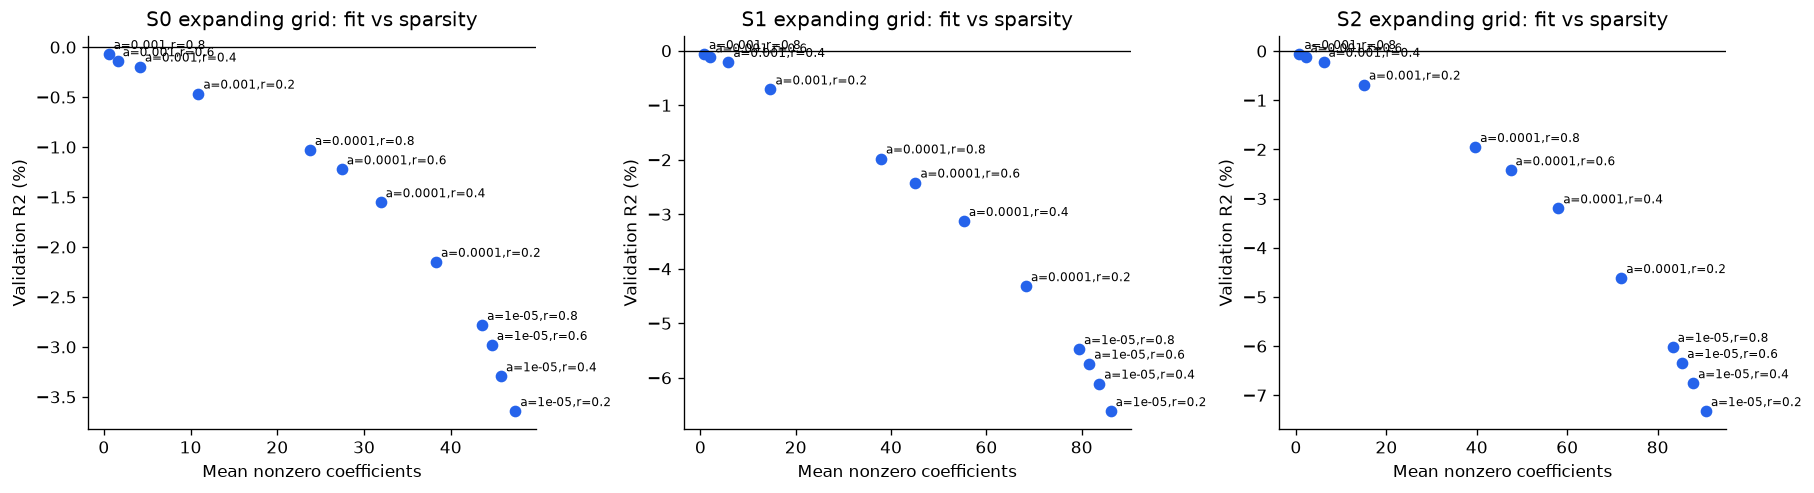

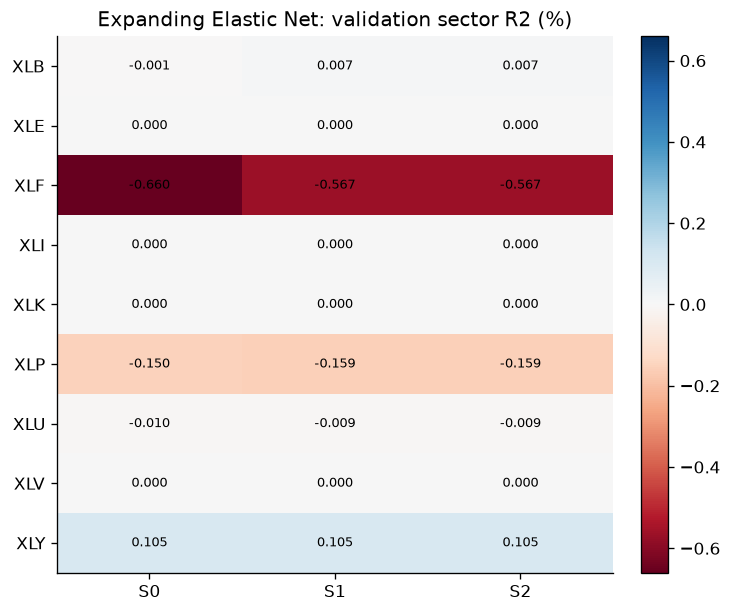

### Pooled MSE vs sector-equal selection

selection_rule,scheme,family,window,pooled_MSE,sector_equal,same_choice
0,S0,ElasticNet,expanding,"a=0.001,r=0.8","a=0.001,r=0.8",True
1,S0,ElasticNet,rolling_3y,"a=0.001,r=0.8","a=0.001,r=0.8",True
2,S0,ElasticNet,rolling_5y,"a=0.001,r=0.8","a=0.001,r=0.8",True
3,S0,Ridge,expanding,lambda=10,lambda=10,True
4,S0,Ridge,rolling_3y,lambda=10,lambda=10,True
5,S0,Ridge,rolling_5y,lambda=10,lambda=10,True
6,S1,ElasticNet,expanding,"a=0.001,r=0.8","a=0.001,r=0.8",True
7,S1,ElasticNet,rolling_3y,"a=0.001,r=0.8","a=0.001,r=0.8",True
8,S1,ElasticNet,rolling_5y,"a=0.001,r=0.8","a=0.001,r=0.8",True
9,S1,Ridge,expanding,lambda=10,lambda=10,True


### Main selected Elastic Net: VALIDATION feature groups

,scheme,feature_group,fraction_fits_using_group,feature_selection_rate
0,S0,aux_,0.2241,0.0112
1,S0,mkt_,0.0019,0.0003
2,S0,own_,0.1611,0.0144
3,S0,state_,0.0000,0.0000
4,S1,aux_,0.2241,0.0112
5,S1,cross_,0.1611,0.0053
6,S1,mkt_,0.0019,0.0003
7,S1,own_,0.1611,0.0138
8,S1,state_,0.0000,0.0000
9,S2,aux_,0.2241,0.0112


# Exploratory validation findings

Selection and comparison use 2018-2022 validation only. The Elastic Net grid is identical to the main pipeline.

144 candidate specifications, 77,760 monthly-sector fits. All use identical validation scoring keys.

Primary criterion: pooled MSE within model/window/scheme. Sector-equal selection is sensitivity analysis.

R2 values below use the SAME expanding-history mean baseline for every window.

All displayed winners are selected on these validation dates; their apparent advantages are selection-biased.

- S0: expanding Elastic Net R2=-0.0691%; lowest explored validation MSE: Ridge/expanding, lambda=10, R2=0.1133%; MSE reduction vs expanding Elastic Net=0.1823%. This is descriptive, not a promoted final model.

- S1: expanding Elastic Net R2=-0.0605%; lowest explored validation MSE: Ridge/expanding, lambda=10, R2=0.1288%; MSE reduction vs expanding Elastic Net=0.1892%. This is descriptive, not a promoted final model.

- S2: expanding Elastic Net R2=-0.0605%; lowest explored validation MSE: Ridge/expanding, lambda=10, R2=0.1307%; MSE reduction vs expanding Elastic Net=0.1911%. This is descriptive, not a promoted final model.

- Selection criteria agree in 18/18 family/window/scheme comparisons.

- Ridge nonzero counts do not demonstrate sparse selection or causal effects.

- Inspect annual and sector tables before interpreting aggregate improvements; avoid cherry-picking years/sectors.

- Section 9 leaves the main locked parameters and the main test/forecast exports unchanged.

- These validation comparisons do not promote an alternative model for the test period.

Validation diagnostics complete. Main forecast exports unchanged by Section 9. Outputs: results/elastic_net/exploratory_validation


### Notes for reading the results

1. R² > 0 means better than the common historical-mean baseline; a small improvement does not imply stable trading value.
2. Every method's parameters are selected on the same validation period, so the best numbers in the tables carry selection bias; the annual plots are descriptive checks.
3. The 3-year window means calendar years; after upstream eligibility filtering it is not guaranteed to contain 756 observations. See the audit table for effective training rows.
4. This section does not change the model locked in the main pipeline; the test and handoff files come from the main run (Sections 6–8).

Effective minimum training rows: {'expanding': 2263, 'rolling_3y': 498, 'rolling_5y': 1003}


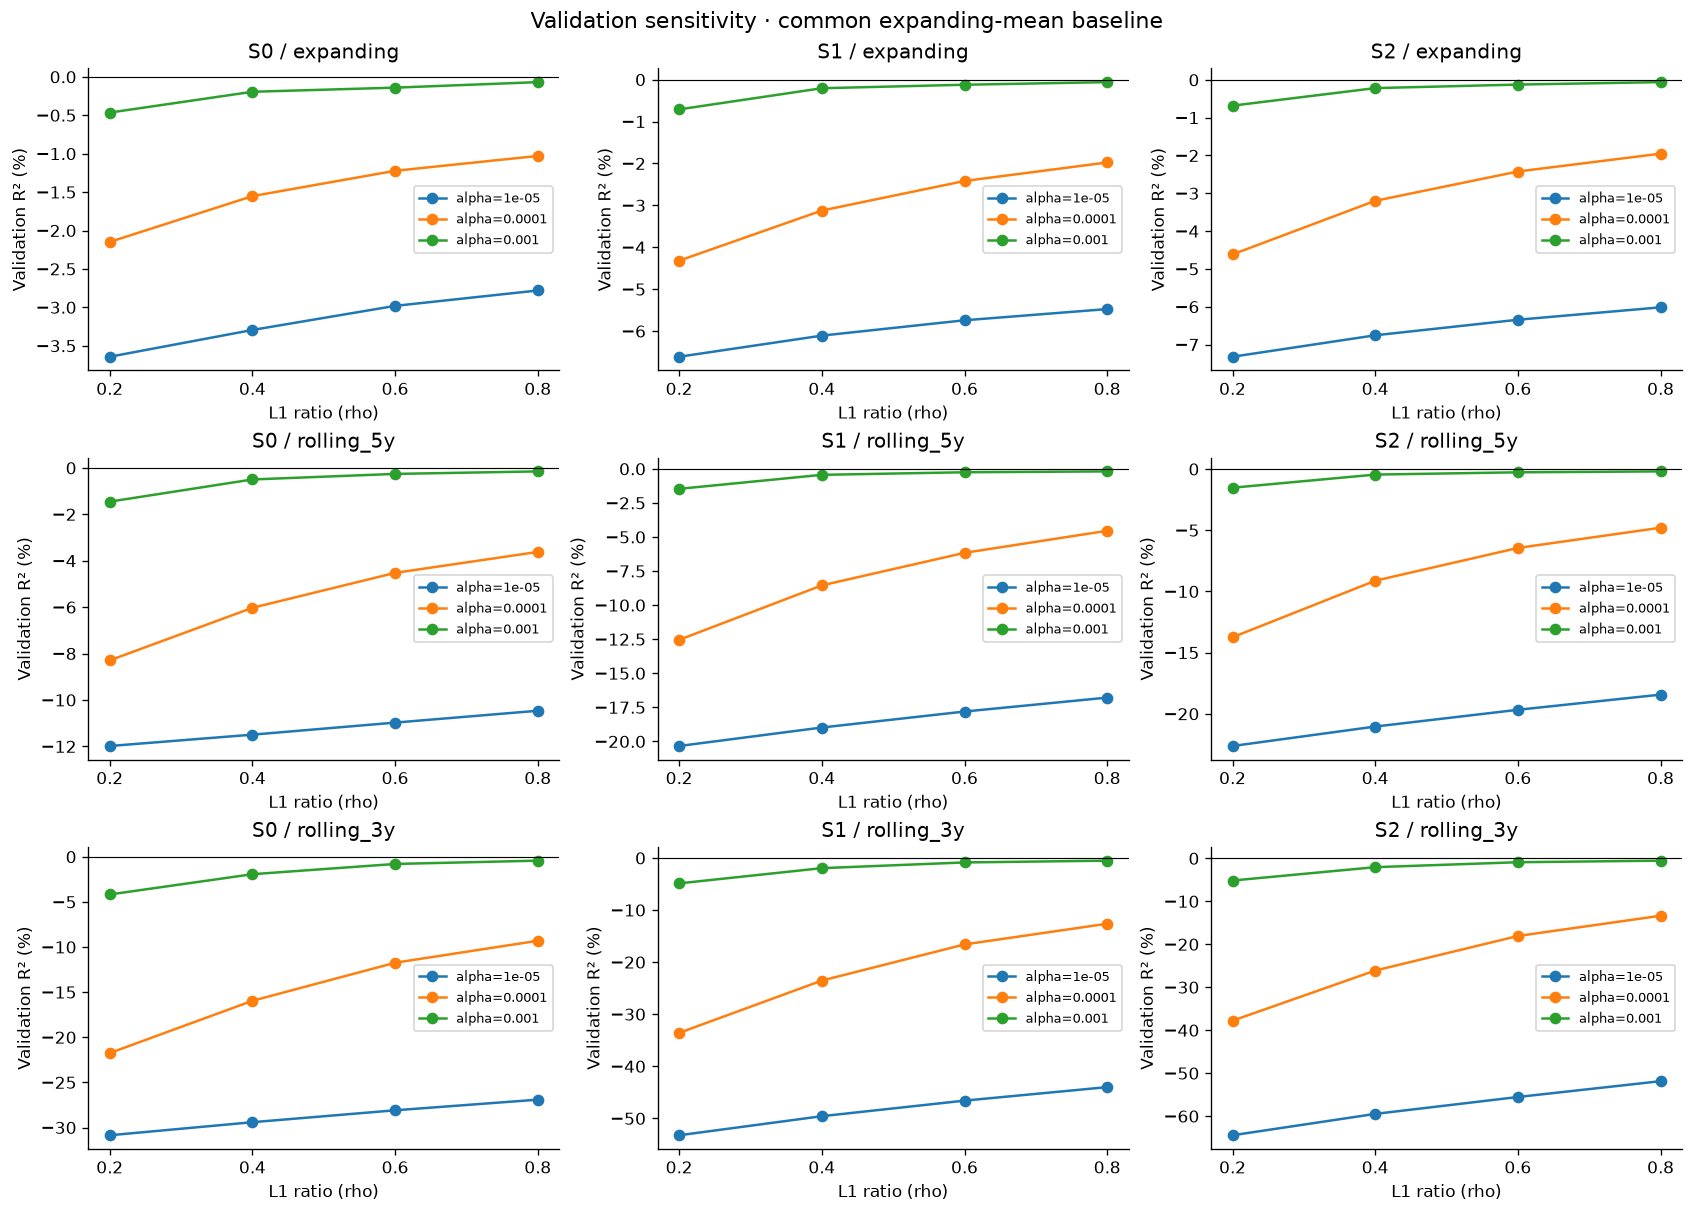

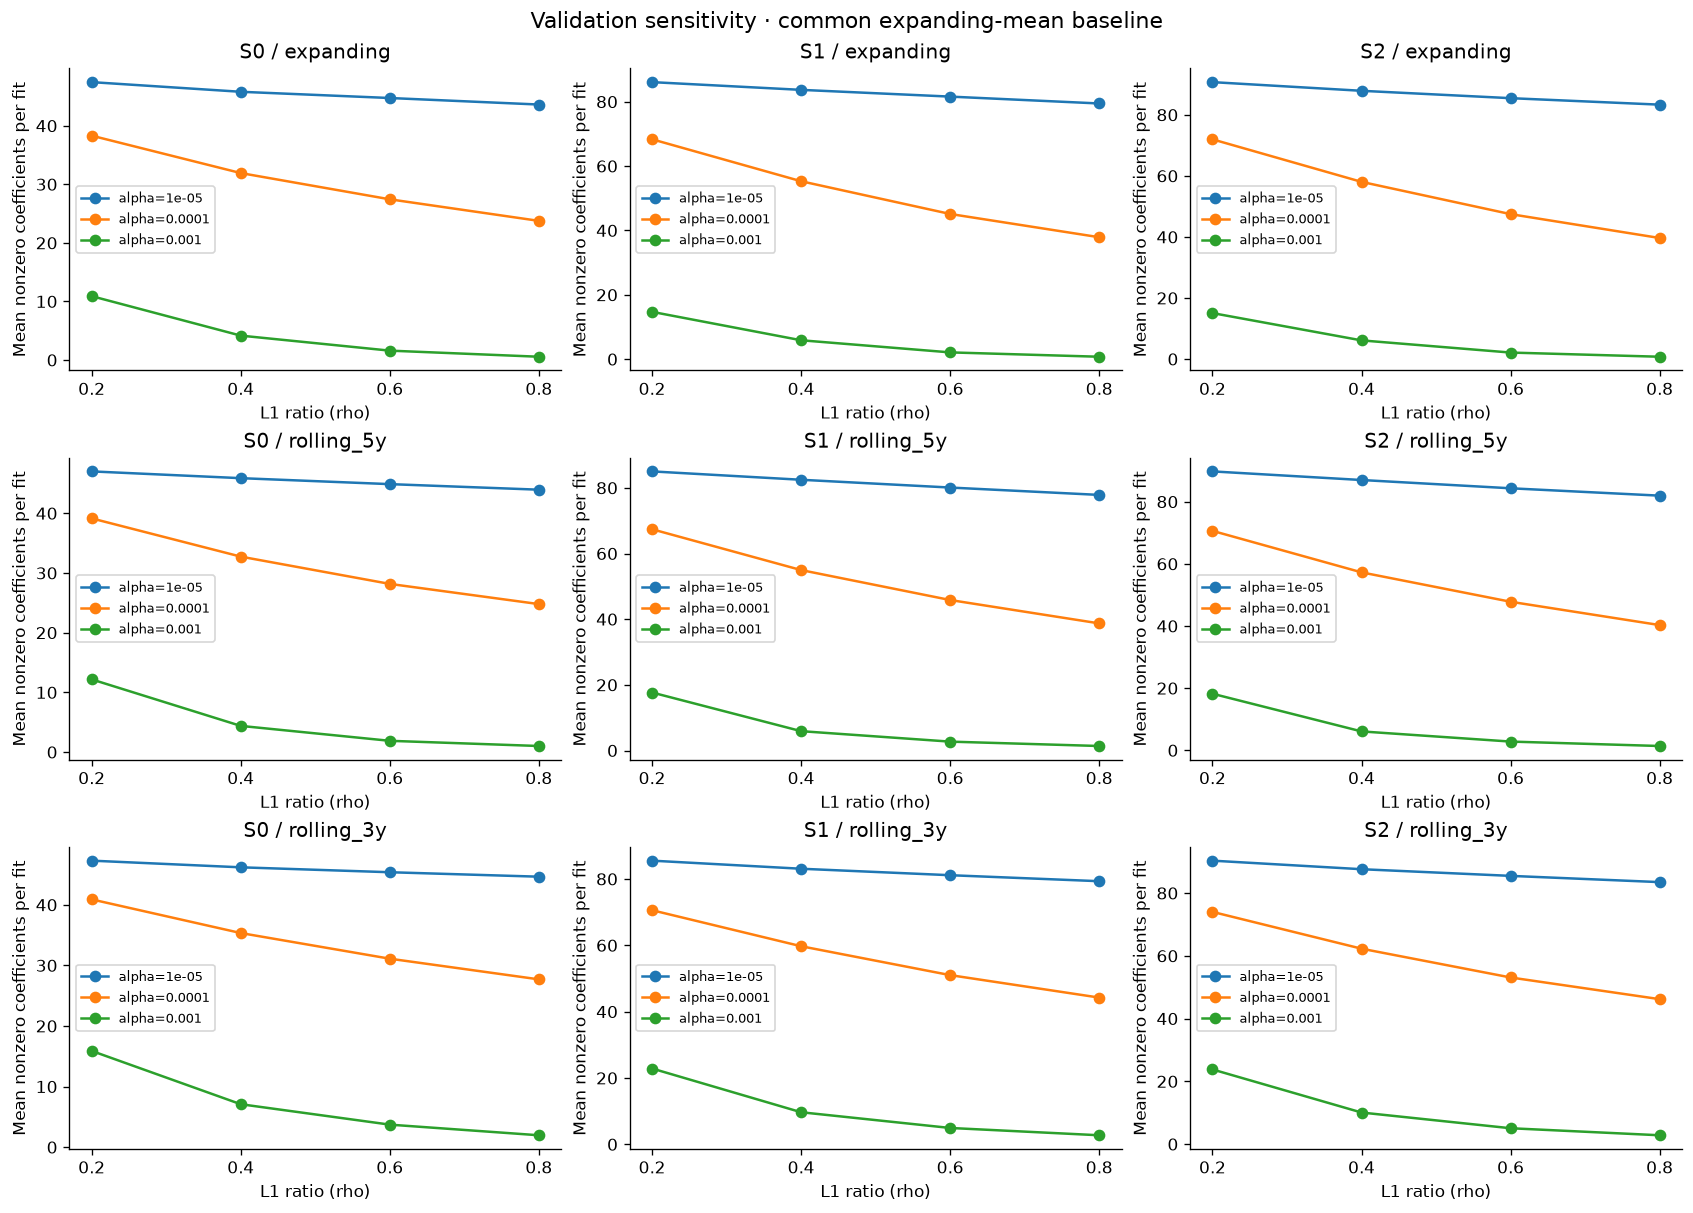

Elastic Net l1_ratio grid check passed: [0.2, 0.4, 0.6, 0.8]


In [16]:
# 9.4 Figures and interpretation; descriptive validation, not a fresh holdout.
ev_primary = ev_choices.loc[ev_choices.selection_rule.eq('pooled_MSE')].copy()
ev_primary['label'] = ev_primary.family+' / '+ev_primary.window
fig, axes = plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
for scheme, ax in zip(EV_SCHEMES,axes):
    g = ev_primary.loc[ev_primary.scheme.eq(scheme)]
    ax.barh(g.label,100*g.R2_common_mean,color=['#64748b' if w=='expanding' else '#0d9488' for w in g.window])
    ax.axvline(0,color='black',lw=.8)
    ax.set(title=scheme+' validation-selected comparisons',xlabel='R2 (%) vs common expanding mean')
fig.savefig(EV_OUT/'01_window_and_model_comparison.png',dpi=160)
plt.show()

fig, axes = plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for scheme, ax in zip(EV_SCHEMES,axes):
    chosen = ev_primary.loc[ev_primary.scheme.eq(scheme),EV_KEYS]
    g = ev_annual.merge(chosen,on=EV_KEYS,validate='many_to_one')
    for (family,window), h in g.groupby(['family','window']):
        ax.plot(h.year,100*h.R2_common_mean,marker='o',label=family+'/'+window)
    ax.axhline(0,color='black',lw=.8)
    ax.set(title=scheme+' annual validation diagnostics',xlabel='Year',ylabel='R2 (%) vs common mean',xticks=range(2018,2023))
axes[-1].legend(fontsize=7)
fig.savefig(EV_OUT/'02_annual_validation_stability.png',dpi=160)
plt.show()

fig, axes = plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for scheme, ax in zip(EV_SCHEMES,axes):
    g = ev_grid.loc[ev_grid.scheme.eq(scheme)&ev_grid.family.eq('ElasticNet')&ev_grid.window.eq('expanding')]
    ax.scatter(g.mean_nonzero,100*g.R2_common_mean,color='#2563eb')
    for r in g.itertuples():
        ax.annotate(r.parameter,(r.mean_nonzero,100*r.R2_common_mean),fontsize=7,xytext=(3,3),textcoords='offset points')
    ax.axhline(0,color='black',lw=.8)
    ax.set(title=scheme+' expanding grid: fit vs sparsity',xlabel='Mean nonzero coefficients',ylabel='Validation R2 (%)')
fig.savefig(EV_OUT/'03_expanding_grid_sparsity.png',dpi=160)
plt.show()

# Original expanding Elastic Net, selected by pooled validation MSE: sector explanations.
ev_orig_keys = ev_primary.loc[ev_primary.family.eq('ElasticNet')&ev_primary.window.eq('expanding'),EV_KEYS]
ev_orig_sector = ev_selected_sectors.merge(ev_orig_keys,on=EV_KEYS,validate='many_to_one')
ev_heat = ev_orig_sector.pivot(index='ticker',columns='scheme',values='R2_common_mean').reindex(index=EV_SECTORS,columns=EV_SCHEMES)*100
fig, ax = plt.subplots(figsize=(6,5),constrained_layout=True)
lim=max(float(np.abs(ev_heat.to_numpy()).max()),.01)
im=ax.imshow(ev_heat,cmap='RdBu',vmin=-lim,vmax=lim,aspect='auto')
ax.set(xticks=range(3),xticklabels=EV_SCHEMES,yticks=range(9),yticklabels=EV_SECTORS,title='Expanding Elastic Net: validation sector R2 (%)')
for i in range(9):
    for j in range(3):
        ax.text(j,i,f'{ev_heat.iloc[i,j]:.3f}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=ax)
fig.savefig(EV_OUT/'04_expanding_validation_sector_heatmap.png',dpi=160)
plt.show()

ev_rule_compare = ev_choices.pivot(index=['scheme','family','window'],columns='selection_rule',values='parameter').reset_index()
ev_rule_compare['same_choice'] = ev_rule_compare.pooled_MSE.eq(ev_rule_compare.sector_equal)
ev_rule_compare.to_csv(EV_OUT/'selection_rule_sensitivity.csv',index=False)
display(Markdown('### Pooled MSE vs sector-equal selection'))
display(ev_rule_compare)

ev_group_view = ev_groups.merge(ev_orig_keys,on=EV_KEYS,validate='many_to_one').groupby(['scheme','feature_group'],as_index=False)[['fraction_fits_using_group','feature_selection_rate']].mean()
display(Markdown('### Main selected Elastic Net: VALIDATION feature groups'))
display(ev_group_view.round(4))

ev_summary_lines = ['# Exploratory validation findings',
    'Selection and comparison use 2018-2022 validation only. The Elastic Net grid is identical to the main pipeline.',
    '144 candidate specifications, 77,760 monthly-sector fits. All use identical validation scoring keys.',
    'Primary criterion: pooled MSE within model/window/scheme. Sector-equal selection is sensitivity analysis.',
    'R2 values below use the SAME expanding-history mean baseline for every window.',
    'All displayed winners are selected on these validation dates; their apparent advantages are selection-biased.']
for scheme in EV_SCHEMES:
    g=ev_primary.loc[ev_primary.scheme.eq(scheme)]
    original=g.loc[g.family.eq('ElasticNet')&g.window.eq('expanding')].iloc[0]
    best=g.sort_values('MSE').iloc[0]
    improvement=100*(1-best.MSE/original.MSE)
    ev_summary_lines.append(f'- {scheme}: expanding Elastic Net R2={original.R2_common_mean:.4%}; lowest explored validation MSE: {best.family}/{best.window}, {best.parameter}, R2={best.R2_common_mean:.4%}; MSE reduction vs expanding Elastic Net={improvement:.4f}%. This is descriptive, not a promoted final model.')
ev_summary_lines += [f'- Selection criteria agree in {int(ev_rule_compare.same_choice.sum())}/{len(ev_rule_compare)} family/window/scheme comparisons.',
    '- Ridge nonzero counts do not demonstrate sparse selection or causal effects.',
    '- Inspect annual and sector tables before interpreting aggregate improvements; avoid cherry-picking years/sectors.',
    '- Section 9 leaves the main locked parameters and the main test/forecast exports unchanged.',
    '- These validation comparisons do not promote an alternative model for the test period.']
assert all(hashlib.sha256(Path(p).read_bytes()).hexdigest()==h for p,h in ev_original_hashes.items()), 'Main forecast export changed during Section 9'
assert all(hashlib.sha256((EV_ROOT/p).read_bytes()).hexdigest()==h for p,h in ev_config['source_hashes'].items()), 'Upstream input changed'
ev_summary_text='\n\n'.join(ev_summary_lines)
(EV_OUT/'exploratory_summary.md').write_text(ev_summary_text+'\n')
(EV_OUT/'completed_checks.json').write_text(json.dumps(dict(fits=len(ev_monthly),candidates=len(ev_grid),
    main_exports_unchanged=True,upstream_inputs_unchanged=True,validation_only=True,
    identical_scored_keys=True,mature_labels_only=True),indent=2)+'\n')
display(Markdown(ev_summary_text))
print('Validation diagnostics complete. Main forecast exports unchanged by Section 9. Outputs:',EV_OUT.relative_to(EV_ROOT))

# Record implementation checks and effective sample sizes for reproducibility.
ev_config['numerical_solver'] = {'elastic_net_max_iter_retries':[10000,100000,1000000],'tol':1e-6,'precompute':True,'ridge_reference_checks_against_sklearn':True,
    'ridge_reference_check_scope':'first validation month, first sector; every window/scheme/lambda',
    'ridge_reference_check_count':len(EV_WINDOWS)*len(EV_SCHEMES)*len(EV_LAMBDAS),
    'ridge_reference_check_rtol':1e-8,'ridge_reference_check_atol':1e-11}
ev_config['minimum_required_training_rows'] = 252
ev_config['minimum_training_rows_rationale'] = 'Approximately one trading year of eligible observations; feasibility guard only, not a performance-tuning parameter.'
ev_config['actual_minimum_training_rows'] = ev_monthly.groupby('window').training_rows.min().astype(int).to_dict()
(EV_OUT/'exploration_config.json').write_text(json.dumps(ev_config,indent=2)+'\n')
display(Markdown('### Notes for reading the results\n\n'
 '1. R² > 0 means better than the common historical-mean baseline; a small improvement does not imply stable trading value.\n'
 '2. Every method\'s parameters are selected on the same validation period, so the best numbers in the tables carry selection bias; the annual plots are descriptive checks.\n'
 '3. The 3-year window means calendar years; after upstream eligibility filtering it is not guaranteed to contain 756 observations. See the audit table for effective training rows.\n'
 '4. This section does not change the model locked in the main pipeline; the test and handoff files come from the main run (Sections 6–8).'))
print('Effective minimum training rows:', ev_config['actual_minimum_training_rows'])


# Fixed-alpha sensitivity for all four ratios, in each window and scheme.
ev_ratio_sensitivity = ev_grid.loc[ev_grid.family.eq('ElasticNet')].sort_values(
    ['window','scheme','alpha','ratio']).copy()
assert len(ev_ratio_sensitivity)==108
assert ev_ratio_sensitivity.groupby(['window','scheme','alpha']).ratio.apply(
    lambda x: list(x)==EV_L1_RATIOS).all()
ev_ratio_sensitivity.to_csv(EV_OUT/'l1_ratio_sensitivity.csv',index=False)
for metric,ylabel,name in [
    ('R2_common_mean','Validation R² (%)','05_r2_vs_l1_ratio.png'),
    ('mean_nonzero','Mean nonzero coefficients per fit','06_nonzero_vs_l1_ratio.png')]:
    fig,axes=plt.subplots(3,3,figsize=(14,10),constrained_layout=True)
    for ri,window in enumerate(EV_WINDOWS):
        for ci,scheme in enumerate(EV_SCHEMES):
            ax=axes[ri,ci]
            g=ev_ratio_sensitivity.loc[ev_ratio_sensitivity.window.eq(window)&ev_ratio_sensitivity.scheme.eq(scheme)]
            for alpha,h in g.groupby('alpha'):
                h=h.sort_values('ratio')
                ax.plot(h.ratio,h[metric]*(100 if metric=='R2_common_mean' else 1),marker='o',label=f'alpha={alpha:g}')
            if metric=='R2_common_mean':ax.axhline(0,color='black',lw=.7)
            ax.set(title=f'{scheme} / {window}',xlabel='L1 ratio (rho)',ylabel=ylabel,xticks=EV_L1_RATIOS)
            ax.legend(fontsize=8)
    fig.suptitle('Validation sensitivity · common expanding-mean baseline',fontsize=13)
    fig.savefig(EV_OUT/name,dpi=160);plt.show()
print('Elastic Net l1_ratio grid check passed:', EV_L1_RATIOS)

## 10. XLF concentration diagnostic

This section examines whether nonzero coefficients and test-period forecast losses are concentrated in XLF, then reports XLF's validation performance under the training windows already evaluated in Section 9. It is descriptive: the locked hyperparameters, training samples, forecasts and main exports are left unchanged. No observations, including 2008–2009, are removed, and no additional model is fitted.

This section reads in-memory objects created by Sections 1–9 and must be run after them in the same kernel. The diagnostics use those in-memory results rather than loading potentially stale forecast or metric files. Outputs from this section are saved separately under `results/elastic_net/xlf_diagnostics/`.

A rolling window changes several historical years at once. Differences between expanding and rolling estimates can suggest sensitivity to older regimes, but cannot identify 2008–2009 as the cause of test underperformance. Validation comparisons below retain the parameters selected across all sectors in Section 9; XLF-specific parameter selection is not introduced.

In [17]:
# Read current-run results without changing any upstream object.
xlf_required = ['coefficient_by_sector', 'test_audit', 'sector_metrics', 'scored',
                'ev_choices', 'ev_monthly', 'ROOT', 'OUT']
xlf_missing = [name for name in xlf_required if name not in globals()]
if xlf_missing:
    raise RuntimeError('Run Sections 1-9 in order before this diagnostic. Missing objects: '
                       + ', '.join(xlf_missing))
xlf_out = OUT / 'xlf_diagnostics'
xlf_out.mkdir(parents=True, exist_ok=True)
xlf_schemes = sorted(test_audit.scheme.unique())
assert 'XLF' in set(test_audit.ticker)
assert not test_audit.duplicated(['scheme', 'month', 'ticker']).any()

### 10.1 Coefficient selection by sector

Report XLF features with a positive selection frequency, alongside all selected sector-feature combinations. The `fits` column supplies the actual denominator; no 45/45 selection claim is assumed. Sector-level counts use the main test-fit audit, with exactly the same nonzero definition as the coefficient summaries. XLF's share is the number of its nonzero coefficient-fit occurrences divided by the corresponding total across all sectors within a scheme; it is not a share of forecast accuracy or a causal attribution.

In [18]:
xlf_coefficient_columns = ['scheme', 'ticker', 'feature', 'fits', 'selection_frequency',
                           'mean_coefficient', 'mean_absolute_coefficient', 'coefficient_std']
xlf_selected_coefficients = coefficient_by_sector.loc[
    coefficient_by_sector.ticker.eq('XLF')
    & coefficient_by_sector.selection_frequency.gt(0), xlf_coefficient_columns
].sort_values(['scheme', 'selection_frequency', 'mean_absolute_coefficient'],
              ascending=[True, False, False]).copy()
xlf_all_selected_coefficients = coefficient_by_sector.loc[
    coefficient_by_sector.selection_frequency.gt(0), xlf_coefficient_columns
].sort_values(['scheme', 'ticker', 'selection_frequency', 'mean_absolute_coefficient'],
              ascending=[True, True, False, False]).copy()
xlf_sector_selection = test_audit.assign(
    has_selected_feature=test_audit.nonzero.gt(0)
).groupby(['scheme', 'ticker'], as_index=False).agg(
    monthly_fits=('nonzero', 'size'),
    fits_with_nonzero=('has_selected_feature', 'sum'),
    mean_nonzero=('nonzero', 'mean'),
    total_nonzero_feature_fits=('nonzero', 'sum'))
xlf_sector_selection['fraction_fits_with_nonzero'] = (
    xlf_sector_selection.fits_with_nonzero / xlf_sector_selection.monthly_fits)
xlf_sector_selection['share_of_nonzero_feature_fits'] = (
    xlf_sector_selection.total_nonzero_feature_fits
    / xlf_sector_selection.groupby('scheme').total_nonzero_feature_fits.transform('sum').replace(0, np.nan))

xlf_selected_coefficients.to_csv(xlf_out / 'xlf_selected_coefficients.csv', index=False)
xlf_all_selected_coefficients.to_csv(xlf_out / 'selected_coefficients_all_sectors.csv', index=False)
xlf_sector_selection.to_csv(xlf_out / 'coefficient_selection_by_sector.csv', index=False)
display(Markdown('#### XLF features selected in at least one locked test fit'))
display(xlf_selected_coefficients.style.format({
    'selection_frequency': '{:.2%}', 'mean_coefficient': '{:.6g}',
    'mean_absolute_coefficient': '{:.6g}', 'coefficient_std': '{:.6g}'}))
display(Markdown('#### Selected features across all sectors'))
display(xlf_all_selected_coefficients)
display(Markdown('#### Sector-level nonzero counts and shares'))
display(xlf_sector_selection.style.format({
    'fraction_fits_with_nonzero': '{:.2%}',
    'share_of_nonzero_feature_fits': '{:.2%}', 'mean_nonzero': '{:.3f}'}))

#### XLF features selected in at least one locked test fit

,scheme,ticker,feature,fits,selection_frequency,mean_coefficient,mean_absolute_coefficient,coefficient_std
151,S0,XLF,own_intraday_1d,45,100.00%,-0.000652926,0.000652926,6.03471e-05
149,S0,XLF,own_excess_SPY_5d,45,100.00%,-0.00041017,0.00041017,4.81408e-05
128,S0,XLF,aux_LQD_cumret_5d,45,100.00%,-8.62096e-05,8.62096e-05,3.50307e-05
784,S1,XLF,own_intraday_1d,45,100.00%,-0.000652926,0.000652926,6.03471e-05
782,S1,XLF,own_excess_SPY_5d,45,100.00%,-0.00041017,0.00041017,4.81408e-05
721,S1,XLF,aux_LQD_cumret_5d,45,100.00%,-8.62096e-05,8.62096e-05,3.50307e-05
1667,S2,XLF,own_intraday_1d,45,100.00%,-0.000652926,0.000652926,6.03471e-05
1665,S2,XLF,own_excess_SPY_5d,45,100.00%,-0.00041017,0.00041017,4.81408e-05
1604,S2,XLF,aux_LQD_cumret_5d,45,100.00%,-8.62096e-05,8.62096e-05,3.50307e-05


#### Selected features across all sectors

,scheme,ticker,feature,fits,selection_frequency,mean_coefficient,mean_absolute_coefficient,coefficient_std
151,S0,XLF,own_intraday_1d,45,1.000000,-0.000653,0.000653,0.000060
149,S0,XLF,own_excess_SPY_5d,45,1.000000,-0.000410,0.000410,0.000048
128,S0,XLF,aux_LQD_cumret_5d,45,1.000000,-0.000086,0.000086,0.000035
460,S0,XLY,aux_HYG_cumret_1d,45,0.133333,-0.000001,0.000001,0.000003
784,S1,XLF,own_intraday_1d,45,1.000000,-0.000653,0.000653,0.000060
782,S1,XLF,own_excess_SPY_5d,45,1.000000,-0.000410,0.000410,0.000048
721,S1,XLF,aux_LQD_cumret_5d,45,1.000000,-0.000086,0.000086,0.000035
1293,S1,XLY,aux_HYG_cumret_1d,45,0.133333,-0.000001,0.000001,0.000003
1667,S2,XLF,own_intraday_1d,45,1.000000,-0.000653,0.000653,0.000060
1665,S2,XLF,own_excess_SPY_5d,45,1.000000,-0.000410,0.000410,0.000048


#### Sector-level nonzero counts and shares

,scheme,ticker,monthly_fits,fits_with_nonzero,mean_nonzero,total_nonzero_feature_fits,fraction_fits_with_nonzero,share_of_nonzero_feature_fits
0,S0,XLB,45,0,0.000,0,0.00%,0.00%
1,S0,XLE,45,0,0.000,0,0.00%,0.00%
2,S0,XLF,45,45,3.000,135,100.00%,95.74%
3,S0,XLI,45,0,0.000,0,0.00%,0.00%
4,S0,XLK,45,0,0.000,0,0.00%,0.00%
5,S0,XLP,45,0,0.000,0,0.00%,0.00%
6,S0,XLU,45,0,0.000,0,0.00%,0.00%
7,S0,XLV,45,0,0.000,0,0.00%,0.00%
8,S0,XLY,45,6,0.133,6,13.33%,4.26%
9,S1,XLB,45,0,0.000,0,0.00%,0.00%


### 10.2 Sector test performance and loss concentration

Report S0's test metrics by sector and plot its OOS R² against the mature historical-mean baseline. To assess aggregate concentration, also decompose each scheme's pooled loss: `excess_sse = model_sse - baseline_sse`. Positive excess SSE means a sector worsens the model's pooled score relative to the baseline. Dividing its negative by total baseline SSE gives that sector's additive contribution to pooled OOS R².

The share of positive excess SSE summarizes concentration among underperforming sectors; it is not the fraction of total model SSE. All ratios are computed from the current scored test observations, and conclusions are generated from the resulting tables rather than assuming XLF is the dominant contributor.

#### S0 test metrics by sector

,ticker,n,RMSE,MAE,R2_OOS_mean,R2_OOS_zero,direction_accuracy
2,XLF,937,0.006947,0.005182,-0.813%,-0.794%,49.73%
8,XLY,937,0.007259,0.005582,-0.000%,-0.106%,47.81%
0,XLB,937,0.008378,0.006320,0.000%,0.066%,52.19%
1,XLE,937,0.014763,0.011130,0.000%,-0.009%,50.59%
3,XLI,937,0.005910,0.004583,0.000%,-0.026%,48.67%
4,XLK,937,0.008196,0.006000,0.000%,0.243%,54.00%
5,XLP,937,0.010667,0.007886,0.000%,0.029%,54.54%
6,XLU,937,0.011481,0.008752,0.000%,0.047%,52.19%
7,XLV,937,0.009318,0.006951,0.000%,-0.076%,47.71%


#### Contributions to pooled test OOS R²

,scheme,ticker,excess_sse,pooled_R2_contribution,share_of_positive_excess_sse
0,S0,XLB,0,-0.0000%,0.00%
1,S0,XLE,0,-0.0000%,0.00%
2,S0,XLF,0.000364823,-0.0473%,99.96%
3,S0,XLI,0,-0.0000%,0.00%
4,S0,XLK,0,-0.0000%,0.00%
5,S0,XLP,0,-0.0000%,0.00%
6,S0,XLU,0,-0.0000%,0.00%
7,S0,XLV,0,-0.0000%,0.00%
8,S0,XLY,1.57413e-07,-0.0000%,0.04%
9,S1,XLB,0,-0.0000%,0.00%


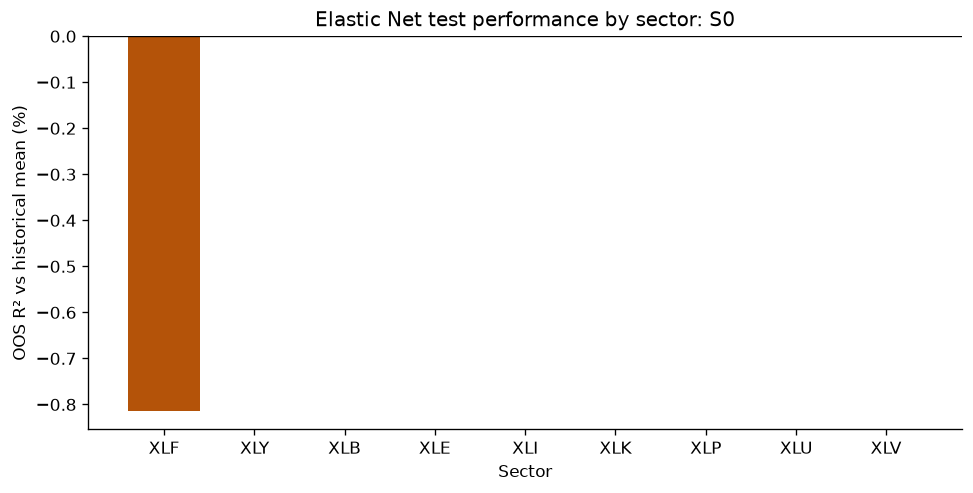

In [19]:
xlf_sector_test_metrics = pd.DataFrame(sector_metrics).loc[
    lambda frame: frame['split'].eq('test')
].copy()
xlf_test_losses = scored.loc[scored['split'].eq('test'),
    ['scheme', 'ticker', 'target_relative_return', 'y_hat', 'historical_mean']].copy()
xlf_test_losses['model_sse'] = (xlf_test_losses.target_relative_return - xlf_test_losses.y_hat)**2
xlf_test_losses['baseline_sse'] = (
    xlf_test_losses.target_relative_return - xlf_test_losses.historical_mean)**2
xlf_loss_by_sector = xlf_test_losses.groupby(['scheme', 'ticker'], as_index=False).agg(
    scored_rows=('model_sse', 'size'), model_sse=('model_sse', 'sum'),
    baseline_sse=('baseline_sse', 'sum'))
assert xlf_loss_by_sector.baseline_sse.gt(0).all()
xlf_loss_by_sector['excess_sse'] = xlf_loss_by_sector.model_sse - xlf_loss_by_sector.baseline_sse
xlf_loss_by_sector['positive_excess_sse'] = xlf_loss_by_sector.excess_sse.clip(lower=0)
xlf_loss_by_sector['pooled_R2_contribution'] = (
    -xlf_loss_by_sector.excess_sse
    / xlf_loss_by_sector.groupby('scheme').baseline_sse.transform('sum'))
xlf_loss_by_sector['share_of_positive_excess_sse'] = (
    xlf_loss_by_sector.positive_excess_sse
    / xlf_loss_by_sector.groupby('scheme').positive_excess_sse.transform('sum').replace(0, np.nan))
xlf_sector_test_metrics = xlf_sector_test_metrics.merge(
    xlf_loss_by_sector, on=['scheme', 'ticker'], validate='one_to_one')
assert xlf_sector_test_metrics.n.eq(xlf_sector_test_metrics.scored_rows).all()
np.testing.assert_allclose(xlf_sector_test_metrics.R2_OOS_mean,
    1 - xlf_sector_test_metrics.model_sse / xlf_sector_test_metrics.baseline_sse,
    rtol=1e-9, atol=1e-12)
xlf_sector_test_metrics.to_csv(xlf_out / 'sector_test_metrics_and_loss_contributions.csv', index=False)
xlf_test_s0 = xlf_sector_test_metrics.loc[
    xlf_sector_test_metrics.scheme.eq('S0')].sort_values('R2_OOS_mean').copy()
display(Markdown('#### S0 test metrics by sector'))
display(xlf_test_s0[['ticker', 'n', 'RMSE', 'MAE', 'R2_OOS_mean',
    'R2_OOS_zero', 'direction_accuracy']].style.format({
        'n': '{:.0f}', 'RMSE': '{:.6f}', 'MAE': '{:.6f}',
        'R2_OOS_mean': '{:.3%}', 'R2_OOS_zero': '{:.3%}',
        'direction_accuracy': '{:.2%}'}))
display(Markdown('#### Contributions to pooled test OOS R²'))
display(xlf_sector_test_metrics[['scheme', 'ticker', 'excess_sse',
    'pooled_R2_contribution', 'share_of_positive_excess_sse']].style.format({
        'excess_sse': '{:.6g}', 'pooled_R2_contribution': '{:.4%}',
        'share_of_positive_excess_sse': '{:.2%}'}))
xlf_fig, xlf_ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
xlf_ax.bar(xlf_test_s0.ticker, 100*xlf_test_s0.R2_OOS_mean,
           color=['#b45309' if ticker == 'XLF' else '#64748b' for ticker in xlf_test_s0.ticker])
xlf_ax.axhline(0, color='black', linewidth=0.8)
xlf_ax.set(title='Elastic Net test performance by sector: S0',
           ylabel='OOS R² vs historical mean (%)', xlabel='Sector')
xlf_fig.savefig(xlf_out / '01_sector_test_r2_s0.png', dpi=180)
plt.show()

### 10.3 XLF validation performance by training window

Use Section 9's pooled-MSE-selected parameter pair for each family, window and scheme, selected across all nine sectors. Join those choices to XLF's monthly validation audit before aggregating SSE. Never sum losses across different parameter candidates or select the best parameter specifically for XLF. Compare expanding, 5-year rolling and 3-year rolling windows against the same expanding historical-mean baseline and identical scoring keys. The table covers all schemes; the figure highlights S0.

Shorter-window improvement, if present, is consistent with sensitivity to older training histories. It does not isolate a crisis-year effect: sample length, included regimes, window-specific scaling and the existing validation-selected parameters can all differ. These comparisons are not used to retune the locked test model.

,scheme,family,window,parameter,months,n,RMSE_bp,R2_common_mean,R2_window_mean,mean_nonzero
0,S0,ElasticNet,expanding,"a=0.001,r=0.8",60,1257,90.691,-0.660%,-0.660%,3.483
1,S0,ElasticNet,rolling_3y,"a=0.001,r=0.8",60,1257,90.681,-0.637%,-0.533%,2.267
2,S0,ElasticNet,rolling_5y,"a=0.001,r=0.8",60,1257,90.489,-0.212%,-0.167%,1.200
3,S0,Ridge,expanding,lambda=10,60,1257,90.364,0.065%,0.065%,57.000
4,S0,Ridge,rolling_3y,lambda=10,60,1257,90.518,-0.276%,-0.172%,57.000
5,S0,Ridge,rolling_5y,lambda=10,60,1257,90.393,0.001%,0.045%,57.000
6,S1,ElasticNet,expanding,"a=0.001,r=0.8",60,1257,90.649,-0.567%,-0.567%,4.767
7,S1,ElasticNet,rolling_3y,"a=0.001,r=0.8",60,1257,90.744,-0.778%,-0.674%,2.767
8,S1,ElasticNet,rolling_5y,"a=0.001,r=0.8",60,1257,90.514,-0.267%,-0.223%,1.483
9,S1,Ridge,expanding,lambda=10,60,1257,90.457,-0.141%,-0.141%,97.000


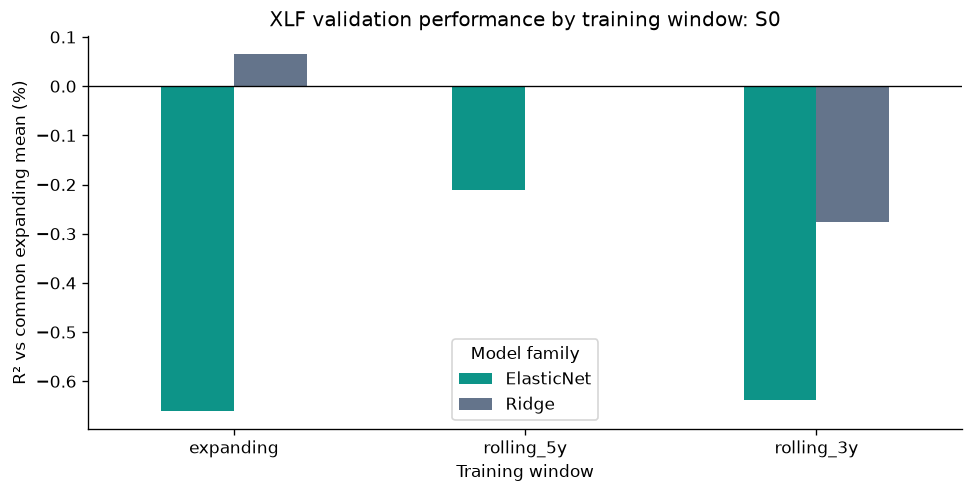

In [20]:
xlf_window_key_columns = ['scheme', 'family', 'window', 'parameter']
xlf_window_choices = ev_choices.loc[ev_choices.selection_rule.eq('pooled_MSE'),
    xlf_window_key_columns].copy()
assert not xlf_window_choices.duplicated(['scheme', 'family', 'window']).any()
xlf_window_months = ev_monthly.loc[ev_monthly.ticker.eq('XLF')].merge(
    xlf_window_choices, on=xlf_window_key_columns, validate='many_to_one')
assert not xlf_window_months.duplicated(xlf_window_key_columns + ['month']).any()
assert xlf_window_months.groupby('month').score_keys_sha256.nunique().eq(1).all()
assert xlf_window_months.groupby('month').base_sse.nunique().eq(1).all()
assert pd.to_datetime(xlf_window_months.latest_label, utc=True).le(
    pd.to_datetime(xlf_window_months.fit_cutoff, utc=True)).all()
xlf_window_validation = xlf_window_months.groupby(xlf_window_key_columns, as_index=False).agg(
    months=('month', 'nunique'), n=('n', 'sum'), model_sse=('sse', 'sum'),
    baseline_sse=('base_sse', 'sum'), window_mean_sse=('own_mean_sse', 'sum'),
    mean_nonzero=('nonzero', 'mean'))
assert xlf_window_validation.months.eq(60).all()
assert xlf_window_validation.groupby('scheme').n.nunique().eq(1).all()
assert xlf_window_validation.baseline_sse.gt(0).all()
xlf_window_validation['R2_common_mean'] = (
    1 - xlf_window_validation.model_sse / xlf_window_validation.baseline_sse)
xlf_window_validation['R2_window_mean'] = (
    1 - xlf_window_validation.model_sse / xlf_window_validation.window_mean_sse)
xlf_window_validation['RMSE_bp'] = (
    np.sqrt(xlf_window_validation.model_sse / xlf_window_validation.n)*10000)
xlf_window_validation = xlf_window_validation.sort_values(['scheme', 'family', 'window'])
xlf_window_validation.to_csv(xlf_out / 'xlf_validation_by_training_window.csv', index=False)
display(xlf_window_validation[['scheme', 'family', 'window', 'parameter', 'months', 'n',
    'RMSE_bp', 'R2_common_mean', 'R2_window_mean', 'mean_nonzero']].style.format({
        'RMSE_bp': '{:.3f}', 'R2_common_mean': '{:.3%}',
        'R2_window_mean': '{:.3%}', 'mean_nonzero': '{:.3f}'}))
xlf_window_order = ['expanding', 'rolling_5y', 'rolling_3y']
xlf_window_plot = xlf_window_validation.loc[xlf_window_validation.scheme.eq('S0')].pivot(
    index='window', columns='family', values='R2_common_mean').reindex(xlf_window_order)
xlf_fig, xlf_ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
(xlf_window_plot*100).plot.bar(ax=xlf_ax, color=['#0d9488', '#64748b'], rot=0)
xlf_ax.axhline(0, color='black', linewidth=0.8)
xlf_ax.set(title='XLF validation performance by training window: S0',
           ylabel='R² vs common expanding mean (%)', xlabel='Training window')
xlf_ax.legend(title='Model family')
xlf_fig.savefig(xlf_out / '02_xlf_validation_r2_by_window_s0.png', dpi=180)
plt.show()

### 10.4 Descriptive reading

The following summary reports computed concentration shares and window differences without assuming their sign. Test diagnostics describe the locked forecasts; window comparisons describe validation-selected models. They do not establish causality or independent evidence for a new model.

XLF’s negative R² under Elastic Net appears in validation (S0, expanding: −0.66%) as well as in test (−0.81%), so it is not specific to the test period. The S0 validation R² improves to −0.21% with a five-year window but falls back to −0.64% with a three-year window; performance therefore does not improve monotonically as the window shortens. Ridge is slightly positive for S0 under expanding training (+0.065%) but negative for S1 and S2. These diagnostics do not identify a cause.


In [21]:
xlf_diagnostic_lines = ['### XLF concentration diagnostic: computed findings']
for xlf_scheme in xlf_schemes:
    xlf_selection_row = xlf_sector_selection.loc[
        xlf_sector_selection.scheme.eq(xlf_scheme)
        & xlf_sector_selection.ticker.eq('XLF')].iloc[0]
    xlf_test_row = xlf_sector_test_metrics.loc[
        xlf_sector_test_metrics.scheme.eq(xlf_scheme)
        & xlf_sector_test_metrics.ticker.eq('XLF')].iloc[0]
    xlf_nonzero_share = xlf_selection_row.share_of_nonzero_feature_fits
    xlf_loss_share = xlf_test_row.share_of_positive_excess_sse
    xlf_selection_text = (f'{xlf_nonzero_share:.2%}' if pd.notna(xlf_nonzero_share)
                          else 'not defined because every test fit is intercept-only')
    xlf_loss_text = (f'{xlf_loss_share:.2%}' if pd.notna(xlf_loss_share)
                     else 'not defined because no sector has positive excess SSE')
    xlf_diagnostic_lines.append(
        f'- {xlf_scheme}: XLF accounts for {xlf_selection_text} of nonzero coefficient-fit '
        f'occurrences. Its test OOS R² is {xlf_test_row.R2_OOS_mean:.3%}; its share '
        f'of positive sector excess SSE is {xlf_loss_text}.')
for (xlf_scheme, xlf_family), xlf_group in xlf_window_validation.groupby(['scheme', 'family']):
    xlf_window_scores = xlf_group.set_index('window').R2_common_mean
    xlf_diagnostic_lines.append(
        f'- XLF {xlf_scheme}/{xlf_family}: validation R² is '
        f'{xlf_window_scores.loc["expanding"]:.3%} (expanding), '
        f'{xlf_window_scores.loc["rolling_5y"]:.3%} (rolling 5y), and '
        f'{xlf_window_scores.loc["rolling_3y"]:.3%} (rolling 3y). '
        'Parameters come from the existing all-sector validation selections.')
xlf_diagnostic_lines.append(
    '- These are descriptive diagnostics only. No model is fitted or retuned, no training '
    'observations are removed, and the differences do not identify a causal 2008-2009 effect.')
xlf_diagnostic_summary = '\n\n'.join(xlf_diagnostic_lines)
display(Markdown(xlf_diagnostic_summary))
(xlf_out / 'xlf_diagnostic_summary.md').write_text(xlf_diagnostic_summary + '\n', encoding='utf-8')
print('Diagnostic outputs:', xlf_out.relative_to(ROOT))

### XLF concentration diagnostic: computed findings

- S0: XLF accounts for 95.74% of nonzero coefficient-fit occurrences. Its test OOS R² is -0.813%; its share of positive sector excess SSE is 99.96%.

- S1: XLF accounts for 95.74% of nonzero coefficient-fit occurrences. Its test OOS R² is -0.813%; its share of positive sector excess SSE is 99.96%.

- S2: XLF accounts for 95.74% of nonzero coefficient-fit occurrences. Its test OOS R² is -0.813%; its share of positive sector excess SSE is 99.96%.

- XLF S0/ElasticNet: validation R² is -0.660% (expanding), -0.212% (rolling 5y), and -0.637% (rolling 3y). Parameters come from the existing all-sector validation selections.

- XLF S0/Ridge: validation R² is 0.065% (expanding), 0.001% (rolling 5y), and -0.276% (rolling 3y). Parameters come from the existing all-sector validation selections.

- XLF S1/ElasticNet: validation R² is -0.567% (expanding), -0.267% (rolling 5y), and -0.778% (rolling 3y). Parameters come from the existing all-sector validation selections.

- XLF S1/Ridge: validation R² is -0.141% (expanding), -0.193% (rolling 5y), and -0.630% (rolling 3y). Parameters come from the existing all-sector validation selections.

- XLF S2/ElasticNet: validation R² is -0.567% (expanding), -0.267% (rolling 5y), and -0.789% (rolling 3y). Parameters come from the existing all-sector validation selections.

- XLF S2/Ridge: validation R² is -0.140% (expanding), -0.190% (rolling 5y), and -0.633% (rolling 3y). Parameters come from the existing all-sector validation selections.

- These are descriptive diagnostics only. No model is fitted or retuned, no training observations are removed, and the differences do not identify a causal 2008-2009 effect.

Diagnostic outputs: results/elastic_net/xlf_diagnostics
